## NCBI Spike sequence download

All the sequences data were retrived from NCBI as of 2026-02-26
type1とtyoe2にわけてこれまでに作成したSpikeのアライメントfileを元にして、一つずつにblastをかけ、hitする配列を落としたのがinput file。ここから重複した配列を除く。

In [15]:
import pandas as pd
from Bio import SeqIO, Entrez
from Bio.Seq import Seq 
import matplotlib as mpl
from matplotlib.font_manager import FontProperties
mpl.rcParams['svg.fonttype'] = 'none'
# Path to your Arial.ttf file
# arial_font_path = '/home/skawakubo/fonts/Arial.ttf'
# Create a FontProperties object for the Arial font
# arial_font = FontProperties(fname=arial_font_path)
# mpl.rcParams['font.family'] = arial_font.get_name()
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time
import subprocess

In [16]:
def fasta_to_dataframe(fasta_file):
    ids = []
    sequences = []
    for record in SeqIO.parse(fasta_file, "fasta"):
        ids.append(record.id)
        sequences.append(str(record.seq))

    df = pd.DataFrame({
        "ID": ids,
        "seq": sequences
    })
    return df

In [19]:
import pandas as pd

# 1. カラム名の定義（これを読み込みと同じセルに入れるのが確実です）
col_names = [
    "qseqid", "qlen", "sseqid", "sacc", "slen", 
    "pident", "length", "mismatch", "gapopen", 
    "qstart", "qend", "sstart", "send", 
    "qcovs", "evalue", "bitscore", "staxids", 
    "sscinames", "scomnames"
]

# 2. Type 1 ファイルの読み込み
FCoV1_S_NCBI_meta_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/blast_result/FCoV_type1_spike_ntblast.out'

FCoV1_S_NCBI_meta = pd.read_csv(
    FCoV1_S_NCBI_meta_path, 
    sep="\t", 
    names=col_names, 
    comment='#',
    skiprows=1 
)

# 3. データの型変換
FCoV1_S_NCBI_meta['slen'] = pd.to_numeric(FCoV1_S_NCBI_meta['slen'], errors='coerce')

# 4. 確認
print(f"Total rows: {len(FCoV1_S_NCBI_meta)}")
FCoV1_S_NCBI_meta.head()

/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_93354/3643316548.py:15: DtypeWarning: Columns (16,17,18) have mixed types. Specify dtype option on import or set low_memory=False.
  FCoV1_S_NCBI_meta = pd.read_csv(


Total rows: 238302


,qseqid,qlen,sseqid,sacc,slen,pident,length,mismatch,gapopen,qstart,qend,sstart,send,qcovs,evalue,bitscore,staxids,sscinames,scomnames
0,PQ416775.1,4407,gi|2236552716|gb|MW815651.1|,MW815651,4407,91.517,4409,370,4,1,4407,1,4407,100,0.0,6067.0,12663,NaN,NaN
1,PQ416775.1,4407,gi|2236552736|gb|MW815661.1|,MW815661,4407,90.229,4411,423,8,1,4407,1,4407,100,0.0,5751.0,12663,NaN,NaN
2,PQ416775.1,4407,gi|2236552738|gb|MW815662.1|,MW815662,4407,90.147,4415,419,12,1,4407,1,4407,100,0.0,5729.0,12663,NaN,NaN
3,PQ416775.1,4407,gi|2056242751|gb|MW316833.1|,MW316833,4395,89.889,4411,426,15,1,4407,1,4395,100,0.0,5657.0,12663,NaN,NaN
4,PQ416775.1,4407,gi|2747347687|gb|PP908788.1|,PP908788,28717,89.508,4413,451,10,1,4407,20093,24499,100,0.0,5574.0,12663,NaN,NaN


In [12]:
len(FCoV1_S_NCBI_meta['sacc'].unique())

7560

In [5]:
# Read the fasta file

FCoV1_Spike_all_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/FCoV1_Spike_all.fasta'
FCoV1_Spike_all = fasta_to_dataframe(FCoV1_Spike_all_path)
FCoV1_Spike_all.rename(columns={"ID": "Accession"}, inplace=True)
FCoV1_Spike_all

,Accession,seq
0,MW815651.1,ATGATAGTTTTACTACTTGCACTCCTTAGCATTGCTAAGTCTGAAG...
1,MW815661.1,ATGATAGTGTTACTACTTGCACTCCTTAGTACTGCTAGCTCTGAAG...
2,MW815662.1,ATGATACTGTTAATATTAGCGCTTCTTAGTACCGCTAGGTCTGAAG...
3,MW316833.1,ATGATGTTGATGATATTTGCACTTCTTAGCATTGCTAAGTCTCAAG...
4,PP908788.1,ATGAGTTCCAAACAATTTAAGATCCTCGTTAATGAGGACTACCAAG...
...,...,...
7555,MK574043.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...
7556,MK574042.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...
7557,MK217373.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...
7558,KF663559.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...


In [17]:
import pandas as pd
import numpy as np

# 1. メタデータの読み込み
FCoV1_S_NCBI_meta_tsv_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/metadata/FCoV1_S_metadata_20260226.tsv'
df = pd.read_csv(FCoV1_S_NCBI_meta_tsv_path, sep="\t")

# 2. 指定されたカラムの順番をリスト化
target_columns = [
    "Accession", "biotype", "Organism_Name", "Isolate", "Species", 
    "Genotype", "Length", "Geo_Location", "Country", "Host", 
    "Tissue_Specimen_Source", "Collection_Date", "Release_Date", 
    "Source", "virus_type"
]

# 3. 不足しているカラムを追加して空欄（NaN）で埋める
# biotype や virus_type など、元データにないものはすべてここで空になります
for col in target_columns:
    if col not in df.columns:
        df[col] = np.nan

# 4. Source だけ NCBI と固定値を入力（virus_type は未記入のまま）
df['Source'] = 'NCBI'

# 5. カラムの順番を並べ替え
df_final = df[target_columns]

# 確認
print("Column Order Check:")
print(df_final.columns.tolist())
print("\nFirst 5 rows:")
print(df_final.head())

# 保存する場合
df_final.to_csv('/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/metadata/FCoV1_S_metadata_organized20260303.tsv', sep='\t', index=False)

Column Order Check:
['Accession', 'biotype', 'Organism_Name', 'Isolate', 'Species', 'Genotype', 'Length', 'Geo_Location', 'Country', 'Host', 'Tissue_Specimen_Source', 'Collection_Date', 'Release_Date', 'Source', 'virus_type']

First 5 rows:
    Accession  biotype                    Organism_Name         Isolate  \
0  OP433735.1      NaN  Porcine epidemic diarrhea virus          S-GDXF   
1  ON263410.1      NaN  Porcine epidemic diarrhea virus        GNU-1809   
2  KU133256.1      NaN  Porcine epidemic diarrhea virus  CH-SDQF-1-2014   
3  MT797682.1      NaN           Human coronavirus 229E         HK05-07   
4  KM975825.1      NaN  Porcine epidemic diarrhea virus             NaN   

       Species  Genotype  Length  Geo_Location  Country          Host  \
0  taxon:28295       NaN    4161           NaN      NaN       porcine   
1  taxon:28295       NaN    4161           NaN      NaN           pig   
2  taxon:28295       NaN    4152           NaN      NaN         swine   
3  taxon:11137  

In [ ]:
# merge
# df_final は上で整理した 15 カラムのデータフレームと仮定
FCoV1_S_NCBI = pd.merge(df_final, FCoV1_Spike_all[['Accession', 'seq']], on="Accession", how="left")

# 2. カラム順の最終調整
# Sequence を一番最後に持ってくる（既存の順序 + Sequence）
current_cols = [col for col in FCoV1_S_NCBI.columns if col != 'seq']
FCoV1_S_NCBI = FCoV1_S_NCBI[current_cols + ['seq']]

# 3. 確認
print(f"Merged size: {FCoV1_S_NCBI.shape}")
print("Column Order:", FCoV1_S_NCBI.columns.tolist())
FCoV1_S_NCBI.head()

Merged size: (7560, 16)
Column Order: ['Accession', 'biotype', 'Organism_Name', 'Isolate', 'Species', 'Genotype', 'Length', 'Geo_Location', 'Country', 'Host', 'Tissue_Specimen_Source', 'Collection_Date', 'Release_Date', 'Source', 'virus_type', 'seq']


,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,virus_type,seq
0,OP433735.1,NaN,Porcine epidemic diarrhea virus,S-GDXF,taxon:28295,NaN,4161,NaN,NaN,porcine,NaN,04-Jun-2021,18-APR-2023,NCBI,NaN,ATGAAGTCTTTAACTTACTTCTGGTTGTTCTTACCAGTACTTTCAA...
1,ON263410.1,NaN,Porcine epidemic diarrhea virus,GNU-1809,taxon:28295,NaN,4161,NaN,NaN,pig,NaN,2018,23-NOV-2022,NCBI,NaN,ATGAAGTCTTTAAATTACTTCTGGTTGTTCTTACCAGTACTTTCAA...
2,KU133256.1,NaN,Porcine epidemic diarrhea virus,CH-SDQF-1-2014,taxon:28295,NaN,4152,NaN,NaN,swine,NaN,06-Mar-2014,29-MAR-2016,NCBI,NaN,ATGAGGTCTTTAAATTACTTCTGGTTGTTCTTACCAGTACTTTCAA...
3,MT797682.1,NaN,Human coronavirus 229E,HK05-07,taxon:11137,NaN,3513,NaN,NaN,Homo sapiens,nasopharyngeal swab,2005-11,02-FEB-2021,NCBI,NaN,ATGTTTGTTTTACTTGTTGCATATGCCTTGTTGCATATTGCTGGTT...
4,KM975825.1,NaN,Porcine epidemic diarrhea virus,NaN,taxon:28295,NaN,2214,NaN,NaN,pig,NaN,13-Feb-2014,09-JUL-2016,NCBI,NaN,ATGAAGTCTTTAACCTACTTCTGGTTGTTCTTACCAGTACTTTCAA...


In [ ]:
# 確認したいクエリIDのリスト swine CoV
target_queries = [
    'NC_028806.1',
    'MT821905.1',
    'MN692770.1',
    'LT545990.1',
    'KR061459.1'
]

print("--- FCoV1_S BLAST Results Summary ---")
for qid in target_queries:
    # 指定した qseqid に一致する行を抽出
    subset = FCoV1_S_NCBI_meta[FCoV1_S_NCBI_meta['qseqid'] == qid]
    
    # その中のユニークな sacc の数をカウント
    unique_sacc_count = subset['sacc'].nunique()
    
    print(f"Query: {qid} -> Unique sacc count: {unique_sacc_count}")

--- FCoV1_S BLAST Results Summary ---
Query: NC_028806.1 -> Unique sacc count: 5057
Query: MT821905.1 -> Unique sacc count: 4974
Query: MN692770.1 -> Unique sacc count: 5057
Query: LT545990.1 -> Unique sacc count: 5063
Query: KR061459.1 -> Unique sacc count: 5057


In [20]:
# uniqueなsaccを取得し、リスト形式に変換
acc_FCoV1_S = FCoV1_S_NCBI_meta['sacc'].unique().tolist()

# 確認（最初の20個を表示）
print(f"Total unique sequences: {len(acc_FCoV1_S)}")
print(acc_FCoV1_S[:20])

Total unique sequences: 7560
['MW815651', 'MW815661', 'MW815662', 'MW316833', 'PP908788', 'MW316834', 'MW316843', 'PP901873', 'PP901871', 'OQ351918', 'MW316838', 'MT239440', 'PV246289', 'MW316830', 'MW815658', 'MW316836', 'FJ938055', 'PV246295', 'MW316847', 'FJ938059']


In [10]:
# リストをテキストファイルとして保存（スパコンで読み込む用）
with open('acc_list_FCoV1.txt', 'w') as f:
    for acc in acc_FCoV1_S:
        f.write(f"{acc}\n")

print(f"Total unique Type 1 sequences: {len(acc_FCoV1_S)}")
print("Saved to acc_list_FCoV1.txt")

Total unique Type 1 sequences: 7560
Saved to acc_list_FCoV1.txt


In [11]:
# Swine CoV のクエリIDリスト
swine_cov_queries = ['NC_028806.1', 'MT821905.1', 'MN692770.1', 'LT545990.1', 'KR061459.1']

# 1. 全体のユニークな sacc を取得 (以前作成した acc_FCoV1_S を利用)
all_sacc_set = set(acc_FCoV1_S)

# 2. Swine CoV をクエリとする sacc を抽出して集合にする
swine_hits = FCoV1_S_NCBI_meta[FCoV1_S_NCBI_meta['qseqid'].isin(swine_cov_queries)]
swine_sacc_set = set(swine_hits['sacc'].unique())

# 3. 差集合をとる（全体から Swine 由来を引き算）
clean_acc_FCoV1_S = list(all_sacc_set - swine_sacc_set)

# 4. 結果の確認
print(f"元々のユニークな件数: {len(all_sacc_set)}")
print(f"Swine CoV 関連として除外された件数: {len(swine_sacc_set)}")
print(f"最終的に残った FCoV1 固有の件数: {len(clean_acc_FCoV1_S)}")

# 最初の20個を表示
print("\n--- Remaining FCoV1 sacc list (first 20) ---")
print(clean_acc_FCoV1_S[:20])

元々のユニークな件数: 7560
Swine CoV 関連として除外された件数: 5064
最終的に残った FCoV1 固有の件数: 2496

--- Remaining FCoV1 sacc list (first 20) ---
['OQ594103', 'PQ626043', 'KX532153', 'DQ112226', 'MG892428', 'OQ594171', 'OQ540911', 'MZ322950', 'JQ304405', 'PV096984', 'FJ917523', 'PQ133182', 'MT797682', 'OY757725', 'PQ466827', 'AY159773', 'EF408013', 'ON554125', 'PP845495', 'KX900393']


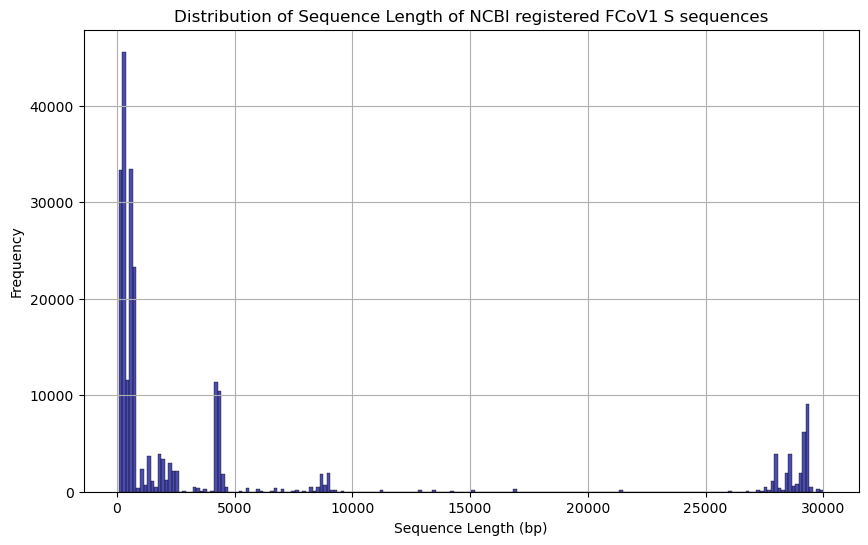

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. 'slen' を数値型に変換（数値にできない文字列は NaN になり、その後削除されます）
FCoV1_S_NCBI_meta['slen'] = pd.to_numeric(FCoV1_S_NCBI_meta['slen'], errors='coerce')

# 2. NaN（変換できなかった行）を念のため除外
plot_data = FCoV1_S_NCBI_meta.dropna(subset=['slen'])

# 3. プロットの実行
plt.figure(figsize=(10, 6))
sns.histplot(plot_data['slen'], bins=200, alpha=0.7, color='darkblue')

plt.title("Distribution of Sequence Length of NCBI registered FCoV1 S sequences")
plt.xlabel("Sequence Length (bp)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

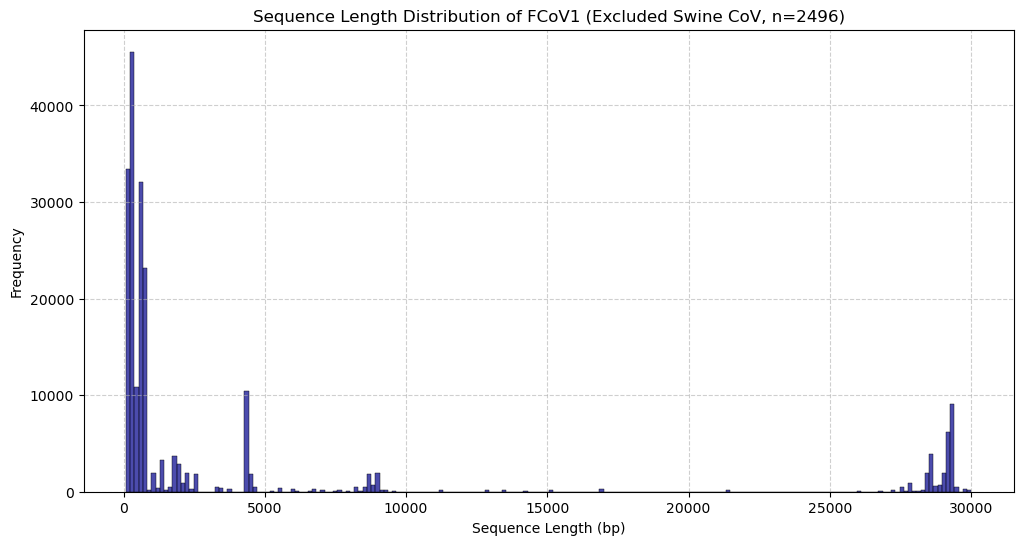

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 除外後リスト (clean_acc_FCoV1_S) に基づいてデータをフィルタリング
# 元のメタデータから、Swineでないものだけを抽出します
plot_data_clean = FCoV1_S_NCBI_meta[FCoV1_S_NCBI_meta['sacc'].isin(clean_acc_FCoV1_S)].copy()

# 2. 数値型への変換とNaN除去
plot_data_clean['slen'] = pd.to_numeric(plot_data_clean['slen'], errors='coerce')
plot_data_clean = plot_data_clean.dropna(subset=['slen'])

# 3. プロット
plt.figure(figsize=(12, 6))
sns.histplot(plot_data_clean['slen'], bins=200, color='darkblue', alpha=0.7)

# グラフの装飾
plt.title(f"Sequence Length Distribution of FCoV1 (Excluded Swine CoV, n={len(clean_acc_FCoV1_S)})")
plt.xlabel("Sequence Length (bp)")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.6)


plt.show()

type2 FCoV-Sも同様に

In [17]:
import pandas as pd

# 1. カラム名の定義（共通）
col_names = [
    "qseqid", "qlen", "sseqid", "sacc", "slen", 
    "pident", "length", "mismatch", "gapopen", 
    "qstart", "qend", "sstart", "send", 
    "qcovs", "evalue", "bitscore", "staxids", 
    "sscinames", "scomnames"
]

# 2. Type 2 ファイルの読み込み
FCoV2_S_NCBI_meta_path = 'FCoV_type2_spike_ntblast.out'

FCoV2_S_NCBI_meta = pd.read_csv(
    FCoV2_S_NCBI_meta_path, 
    sep="\t", 
    names=col_names,  # 定義したカラム名を割り当て
    comment='#',      # '#' で始まるBLASTのヘッダー行を無視
    skiprows=1
)

# 3. データの型変換（前回のTypeError対策）
FCoV2_S_NCBI_meta['slen'] = pd.to_numeric(FCoV2_S_NCBI_meta['slen'], errors='coerce')

# 4. 確認
print(f"Total rows: {len(FCoV2_S_NCBI_meta)}")
FCoV2_S_NCBI_meta.head()

Total rows: 153311


/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_50078/3277996231.py:15: DtypeWarning: Columns (16,17,18) have mixed types. Specify dtype option on import or set low_memory=False.
  FCoV2_S_NCBI_meta = pd.read_csv(


,qseqid,qlen,sseqid,sacc,slen,pident,length,mismatch,gapopen,qstart,qend,sstart,send,qcovs,evalue,bitscore,staxids,sscinames,scomnames
0,NC_002306.3,4357,gi|2708442415|gb|PP526173.1|,PP526173,29356,99.954,4359,0,1,1,4357,20436,24794,100,0.0,8037.0,11135,NaN,NaN
1,NC_002306.3,4357,gi|28916157|gb|AY204704.1|,AY204704,14201,99.954,4359,0,1,1,4357,1071,5429,100,0.0,8037.0,222558,NaN,NaN
2,NC_002306.3,4357,gi|556925467|gb|KC461237.1|,KC461237,29357,99.954,4359,0,1,1,4357,20436,24794,100,0.0,8037.0,11135,NaN,NaN
3,NC_002306.3,4357,gi|422313307|gb|KC175339.1|,KC175339,29270,99.954,4359,0,1,1,4357,20411,24769,100,0.0,8037.0,11153,NaN,NaN
4,NC_002306.3,4357,gi|315192962|ref|NC_002306.3|,NC_002306,29355,99.954,4359,0,1,1,4357,20436,24794,100,0.0,8037.0,11135,NaN,NaN


In [18]:
# 重複のないアクセッション番号リストを作成
acc_FCoV2_S = FCoV2_S_NCBI_meta['sacc'].unique().tolist()

print(f"Total unique Type 2 sequences: {len(acc_FCoV2_S)}")

Total unique Type 2 sequences: 1599


In [19]:
# リストをテキストファイルとして保存（スパコンで読み込む用）
with open('acc_list_FCoV2.txt', 'w') as f:
    for acc in acc_FCoV2_S:
        f.write(f"{acc}\n")

print(f"Total unique Type 2 sequences: {len(acc_FCoV2_S)}")
print("Saved to acc_list_FCoV2.txt")

Total unique Type 2 sequences: 1599
Saved to acc_list_FCoV2.txt


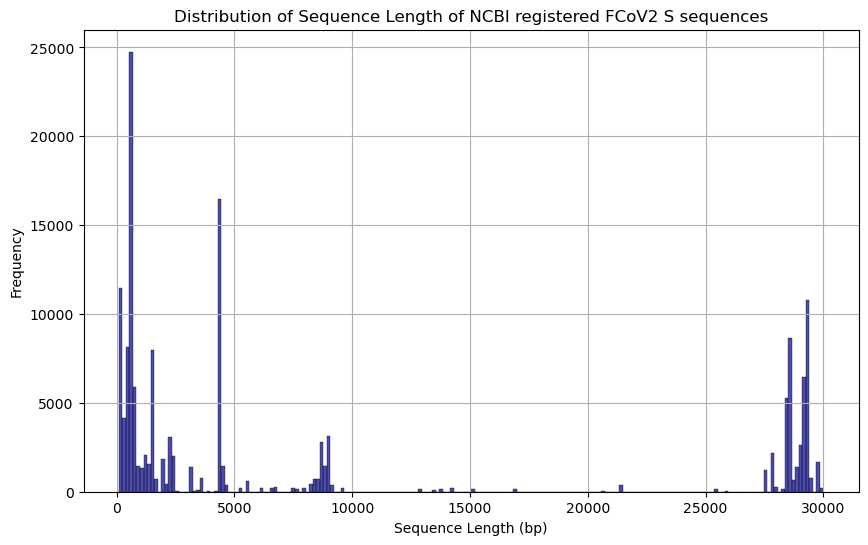

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
# NaNを除外してプロット
sns.histplot(FCoV2_S_NCBI_meta['slen'].dropna(), bins=200, alpha=0.7, color='darkblue') 

plt.title("Distribution of Sequence Length of NCBI registered FCoV2 S sequences")
plt.xlabel("Sequence Length (bp)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

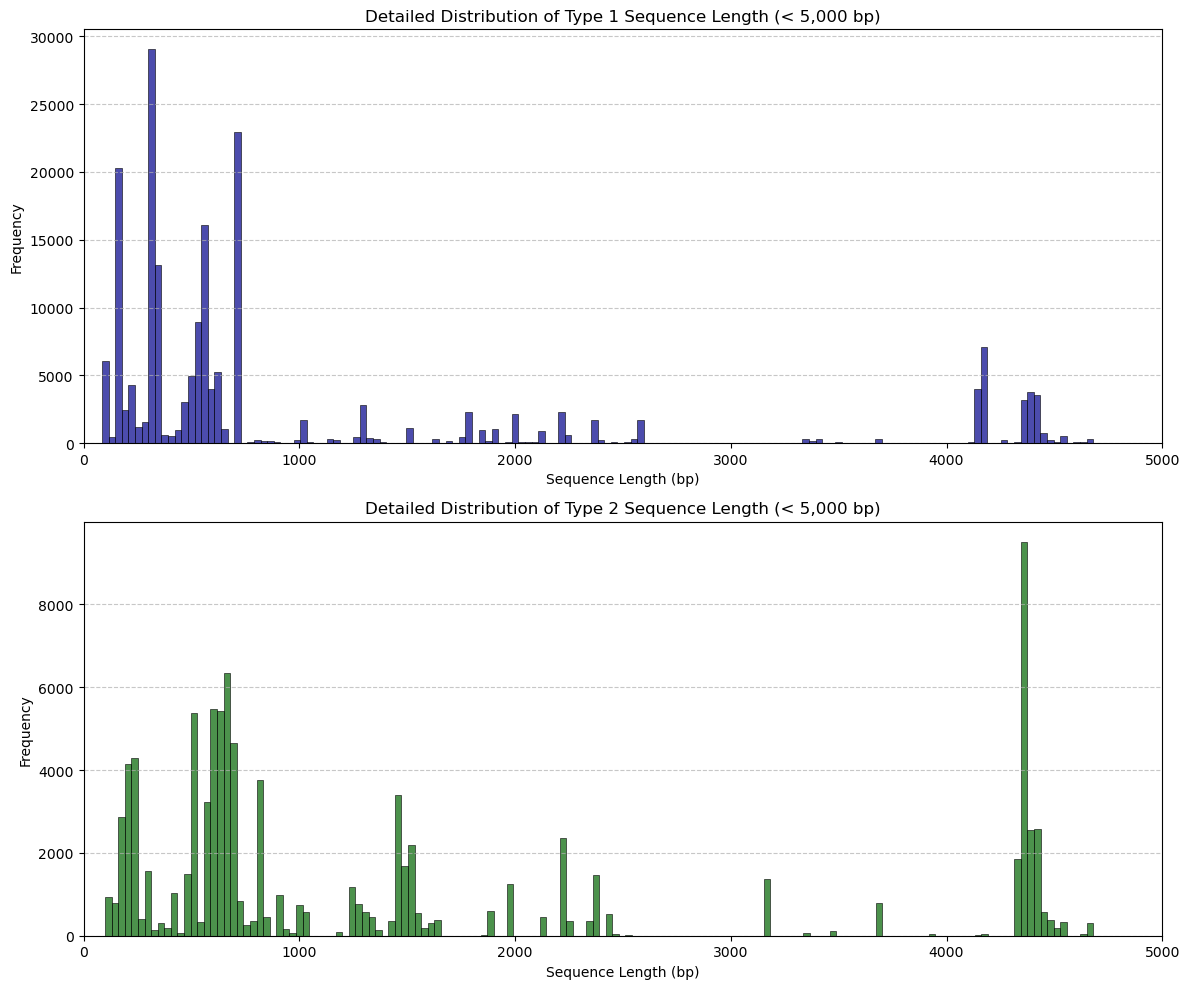

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# 解析したいデータフレームのリスト
datasets = [
    {'df': FCoV1_S_NCBI_meta, 'name': 'Type 1', 'color': 'darkblue'},
    {'df': FCoV2_S_NCBI_meta, 'name': 'Type 2', 'color': 'darkgreen'}
]

# 2つのグラフを並べて表示（または個別に詳細表示）
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=False)

for i, data in enumerate(datasets):
    # 4400bp未満のデータのみを抽出
    target_data = data['df'][data['df']['slen'] < 5000]['slen'].dropna()
    
    sns.histplot(target_data, bins=150, ax=axes[i], color=data['color'], alpha=0.7)
    
    axes[i].set_title(f"Detailed Distribution of {data['name']} Sequence Length (< 5,000 bp)")
    axes[i].set_xlabel("Sequence Length (bp)")
    axes[i].set_ylabel("Frequency")
    axes[i].set_xlim(0, 5000) # 範囲を0-5000に固定
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [4]:
# 3000-25000 bpにfilter
# Type 1 のカウント
df1_selected = FCoV1_S_NCBI_meta[(FCoV1_S_NCBI_meta['slen'] >= 3000) & (FCoV1_S_NCBI_meta['slen'] < 25000)]
acc_FCoV1_S_filtered = df1_selected['sacc'].unique().tolist()

# Type 2 のカウント
df2_selected = FCoV2_S_NCBI_meta[(FCoV2_S_NCBI_meta['slen'] >= 3000) & (FCoV2_S_NCBI_meta['slen'] < 25000)]
acc_FCoV2_S_filtered = df2_selected['sacc'].unique().tolist()

print(f"Type 1: {len(acc_FCoV1_S_filtered)} sequences match criteria.")
print(f"Type 2: {len(acc_FCoV2_S_filtered)} sequences match criteria.")

NameError: name 'FCoV1_S_NCBI_meta' is not defined

In [24]:
# 1. Swine CoV のクエリIDリストを定義
swine_cov_queries = ['NC_028806.1', 'MT821905.1', 'MN692770.1', 'LT545990.1', 'KR061459.1']

# 2. 全体のフィルタリング（3,000 bp以上 25,000 bp未満）を行い、ユニークな sacc を集合(set)にする
all_filtered_sacc = set(FCoV1_S_NCBI_meta[
    (FCoV1_S_NCBI_meta['slen'] >= 3000) & (FCoV1_S_NCBI_meta['slen'] < 25000)
]['sacc'].unique())

# 3. Swine CoV をクエリとする行から、ユニークな sacc を抽出して集合(set)にする
swine_hits = FCoV1_S_NCBI_meta[FCoV1_S_NCBI_meta['qseqid'].isin(swine_cov_queries)]
swine_sacc_set = set(swine_hits['sacc'].unique())

# 4. 差集合をとる（全体から Swine 由来を差し引く）
clean_acc_FCoV1_S = list(all_filtered_sacc - swine_sacc_set)

# 5. 結果の表示
print(f"3000-25000bpでフィルタリング済み件数: {len(all_filtered_sacc)}")
print(f"Swine CoVに関連して除外された件数: {len(swine_sacc_set)}")
print(f"最終的に残った FCoV1 候補件数: {len(clean_acc_FCoV1_S)}")

3000-25000bpでフィルタリング済み件数: 2706
Swine CoVに関連して除外された件数: 5064
最終的に残った FCoV1 候補件数: 335


NCBIからfastaと同様にmetadataをダウンロード

In [29]:
acc_FCoV1_S

['MW815651',
 'MW815661',
 'MW815662',
 'MW316833',
 'PP908788',
 'MW316834',
 'MW316843',
 'PP901873',
 'PP901871',
 'OQ351918',
 'MW316838',
 'MT239440',
 'PV246289',
 'MW316830',
 'MW815658',
 'MW316836',
 'FJ938055',
 'PV246295',
 'MW316847',
 'FJ938059',
 'FJ938062',
 'MW316835',
 'MW316841',
 'OK340213',
 'MW316846',
 'KY292377',
 'FJ938052',
 'KX722529',
 'MW815650',
 'OP542206',
 'OQ351917',
 'PP254212',
 'MW316840',
 'MW815659',
 'HQ012370',
 'PP901872',
 'FJ938060',
 'PV246309',
 'KU215422',
 'KU215421',
 'KU215420',
 'KU215419',
 'MW815656',
 'FJ938053',
 'KU215423',
 'MW815660',
 'MW815654',
 'KU215425',
 'MW815653',
 'KU215428',
 'MW815655',
 'KU215426',
 'PV246290',
 'MW316839',
 'HQ012368',
 'PP254209',
 'MW316831',
 'PV246294',
 'KU215424',
 'PV246296',
 'MW030110',
 'MW316842',
 'MW316844',
 'PP901876',
 'ON595872',
 'HQ392469',
 'PP854701',
 'DQ160294',
 'PP854702',
 'AB695067',
 'PP901875',
 'MW316832',
 'HQ012372',
 'PV246323',
 'PP901877',
 'PV246297',
 'ON595873',

In [30]:
Entrez.email = 'iz-kida@czc.hokudai.ac.jp'

net_handle = Entrez.efetch(db="nucleotide", id=list(set(acc_FCoV1_S)), rettype="gb", retmode="text")
with open('acc_FCoV1_S_20260226.gbk', 'w') as out:
    out.write(net_handle.read())

In [27]:
acc_FCoV2_S

['PP526173',
 'AY204704',
 'KC461237',
 'KC175339',
 'NC_002306',
 'X06170',
 'OQ311325',
 'OQ311324',
 'OQ311323',
 'KC461236',
 'KC461235',
 'PQ192636',
 'PQ202302',
 'MW030109',
 'DQ010921',
 'AY452031',
 'JQ408981',
 'JQ408980',
 'DQ286389',
 'OR295209',
 'MK987175',
 'KY063618',
 'KY063617',
 'KY063616',
 'JQ404410',
 'PP526171',
 'JN634064',
 'X80799',
 'AB017789',
 'AB781790',
 'AB781788',
 'AB781789',
 'MW316851',
 'KP981644',
 'DQ112226',
 'EF192155',
 'GU146061',
 'OQ351915',
 'MT114551',
 'OQ351913',
 'ON107244',
 'OQ351912',
 'OM055788',
 'GQ152141',
 'PV246303',
 'PV246298',
 'MW316848',
 'OK340208',
 'OQ351916',
 'OK340207',
 'OK340209',
 'MT114548',
 'MT114547',
 'OK340211',
 'MT114552',
 'MT114545',
 'PV246300',
 'MT166676',
 'MT114546',
 'PV246302',
 'PV246299',
 'MW186440',
 'MT114550',
 'JF682842',
 'MT114539',
 'MT114542',
 'MT166675',
 'MT114549',
 'MT114544',
 'MT114540',
 'PV246312',
 'PV246304',
 'MT166674',
 'MT239439',
 'PV246311',
 'PV246284',
 'LC190906',
 '

In [28]:
Entrez.email = 'iz-kida@czc.hokudai.ac.jp'

net_handle = Entrez.efetch(db="nucleotide", id=list(set(acc_FCoV2_S)), rettype="gb", retmode="text")
with open('acc_FCoV2_S_20260226.gbk', 'w') as out:
    out.write(net_handle.read())

In [35]:
from Bio import SeqIO
import pandas as pd

gbk_file = 'acc_FCoV1_S_20260226.gbk' # FCoV1用のファイル名
metadata_list = []

print("Parsing GenBank file...")

for record in SeqIO.parse(gbk_file, "genbank"):
    info = {
        "Accession": record.id,
        "Organism_Name": record.annotations.get("organism", ""),
        "Length": len(record.seq),
        "Release_Date": record.annotations.get("date", ""),
        # "seq" はメモリ節約のため除外
    }
    
    if record.features:
        source_feature = record.features[0]
        if source_feature.type == "source":
            quals = source_feature.qualifiers
            info["Isolate"] = quals.get("isolate", [""])[0]
            info["Species"] = quals.get("db_xref", [""])[0]
            info["Genotype"] = quals.get("genotype", [""])[0]
            
            geo = quals.get("country", [""])[0]
            info["Geo_Location"] = geo
            info["Country"] = geo.split(":")[0] if ":" in geo else geo
            
            info["Host"] = quals.get("host", [""])[0]
            info["Tissue_Specimen_Source"] = quals.get("isolation_source", [""])[0]
            info["Collection_Date"] = quals.get("collection_date", [""])[0]

    metadata_list.append(info)

# データフレーム作成
df_FCoV1_meta = pd.DataFrame(metadata_list)

# 並び替え（seqなし）
columns_order = [
    "Accession", "Organism_Name", "Isolate", "Species", "Genotype", 
    "Length", "Geo_Location", "Country", "Host", 
    "Tissue_Specimen_Source", "Collection_Date", "Release_Date"
]
df_FCoV1_meta = df_FCoV1_meta[columns_order]

# CSVとして保存
output_csv = 'FCoV1_S_metadata_20260226.csv'
df_FCoV1_meta.to_csv(output_csv, index=False)

print(f"Success! Metadata saved to {output_csv}")
print(f"Total records: {len(df_FCoV1_meta)}")

Parsing GenBank file...
Success! Metadata saved to FCoV1_S_metadata_20260226.csv
Total records: 7560


In [36]:
from Bio import SeqIO
import pandas as pd

gbk_file = 'acc_FCoV2_S_20260226.gbk' # FCoV2用のファイル名
metadata_list = []

print("Parsing GenBank file...")

for record in SeqIO.parse(gbk_file, "genbank"):
    info = {
        "Accession": record.id,
        "Organism_Name": record.annotations.get("organism", ""),
        "Length": len(record.seq),
        "Release_Date": record.annotations.get("date", ""),
        # "seq" はメモリ節約のため除外
    }
    
    if record.features:
        source_feature = record.features[0]
        if source_feature.type == "source":
            quals = source_feature.qualifiers
            info["Isolate"] = quals.get("isolate", [""])[0]
            info["Species"] = quals.get("db_xref", [""])[0]
            info["Genotype"] = quals.get("genotype", [""])[0]
            
            geo = quals.get("country", [""])[0]
            info["Geo_Location"] = geo
            info["Country"] = geo.split(":")[0] if ":" in geo else geo
            
            info["Host"] = quals.get("host", [""])[0]
            info["Tissue_Specimen_Source"] = quals.get("isolation_source", [""])[0]
            info["Collection_Date"] = quals.get("collection_date", [""])[0]

    metadata_list.append(info)

# データフレーム作成
df_FCoV2_meta = pd.DataFrame(metadata_list)

# 並び替え（seqなし）
columns_order = [
    "Accession", "Organism_Name", "Isolate", "Species", "Genotype", 
    "Length", "Geo_Location", "Country", "Host", 
    "Tissue_Specimen_Source", "Collection_Date", "Release_Date"
]
df_FCoV2_meta = df_FCoV2_meta[columns_order]

# CSVとして保存
output_csv = 'FCoV2_S_metadata_20260226.csv'
df_FCoV2_meta.to_csv(output_csv, index=False)

print(f"Success! Metadata saved to {output_csv}")
print(f"Total records: {len(df_FCoV2_meta)}")

Parsing GenBank file...
Success! Metadata saved to FCoV2_S_metadata_20260226.csv
Total records: 1599


NCBIからダウンロードしたSpikeをtreeからFCoVとFCoV likeな配列を抜き出して、25Kb以上の配列で作成したmetaと合わせてユニークなものを絞る

In [28]:
list_FCoV1_Spike_NCBI = ['FJ917527.1','HE860474.1','HE860468.1','HE860469.1','HE860477.1','KP143510.1','KP143511.1','KP143509.1','HE860473.1','HE860466.1','HE860478.1','HE860472.1','HE860475.1','HE860471.1','MT606060.1','MT606085.1','MT606072.1','MT606050.1','MT606095.1','MT606057.1','MT606100.1','MT606098.1','MT606056.1','MT606090.1','MT606031.1','MT606036.1','MT606046.1','MT606018.1','MT606084.1','MT606088.1','MT606062.1','MT606089.1','MT606087.1','MT606068.1','MT606024.1','MT606078.1','MT606075.1','MT606063.1','MT606102.1','MT606103.1','MT606099.1','MT606041.1','MT606091.1','MT606074.1','MT606093.1','MT606047.1','MT606101.1','MT606080.1','MT606058.1','MT606071.1','MT606082.1','MT606079.1','MT606029.1','MT606048.1','MT606077.1','MT606076.1','MT606097.1','MT606020.1','MT606035.1','MT606040.1','MT606067.1','MT606038.1','MT606052.1','MT606049.1','MT606061.1','MT606033.1','MT606053.1','MT606070.1','MT606039.1','MT606022.1','MT606044.1','MT606037.1','MT606027.1','MT606092.1','MT606051.1','MT606026.1','MT606019.1','MT606081.1','MT606073.1','MT606034.1','MT606054.1','MT606028.1','MT606023.1','MT606083.1','MT606045.1','MT606059.1','MT606032.1','DQ256137.1','LC671508.1','LC671509.1','LC671510.1','LC671489.1','LC671491.1','LC671475.1','LC671490.1','LC671469.1','EF407998.1','EU327751.1','EU327722.1','KF312726.1','KF668591.1','GU324419.1','KF312728.1','OP422909.1','OQ974949.1','OP597274.1','AY307020.1','AY170345.1','MF536801.1','KP849472.1','AY307021.1','OK340206.1','OK340205.1','OK340204.1','MK986782.1','MK986787.1','JX035857.1','LC753477.1','LC753476.1','KT222995.1','KF312719.1','KF312720.1','MK986778.1','MK986780.1','MK986771.1','KF312718.1','OP422906.1','OP422911.1','KP322041.1','MK986779.1','JX035837.1','JX035838.1','JX035860.1','JX035844.1','MK986768.1','MH603132.2','OP422912.1','OP422907.1','OP422908.1','OP422910.1','OP422913.1','OP422915.1','KF312723.1','LC753475.1','KF312724.1','MK986769.1','MK986770.1','MT551867.1','MT551869.1','MT551868.1','HG325837.1','OQ196091.1','OQ407517.1','EU664180.1','EU664183.1','EU664182.1','OK236295.1','AF533349.1','AF533350.1','MW225994.1','MW225993.1','MW225960.1','MW225989.1','MW225998.1','PQ641433.1','PQ641444.1','PQ641439.1','PQ641438.1','PQ561644.1','PQ641434.1','PQ641432.1','PQ641440.1','HF954948.1','HF954928.1','HF954965.1','PQ641437.1','HF954937.1','HF954946.1','HF954950.1','HF954956.1','HF954955.1','HF954963.1','HF954927.1','HF954943.1','HF954962.1','PQ641443.1','PQ641436.1','PQ641442.1','PQ641431.1','PQ641435.1','PQ641441.1','HF954964.1','HF954949.1','HF954952.1','HF954967.1','HF954947.1','HF954970.1','HF954938.1','HF954936.1','HF954934.1','PQ641430.1','HF954935.1','HF954971.1','HF954929.1','HF954931.1','HF954942.1','MF357053.1','PQ626040.1','MG560053.1','KM213244.1','MG560052.1','KM213246.1','KM213249.1','KM213247.1','KM213248.1','HF954957.1','HF954932.1','HF954966.1','PQ565823.1','PQ565822.1','HF954951.1','HF954933.1','HF954930.1','MZ221045.1','HF954953.1','MZ221042.1','HF954958.1','HF954959.1','MZ221036.1','MZ221041.1','MZ221038.1','MZ221046.1','HF954975.1','HF954974.1','HF954972.1','HF954969.1','HF954968.1','ON595883.1','ON595884.1','ON595877.1','ON595874.1','ON595878.1','ON595880.1','ON595881.1','MW648563.1','AY159751.1','MG892452.1','OK236321.1','MG016699.1','EU327723.1','EU327746.1','LC671493.1','LC671479.1','MG016693.1','EU327752.1','MG016696.1','OQ196070.1','OK236303.1','OK236302.1','EU513382.1','LC671517.1','MW858301.1','MF357050.1','MF357035.1','MF357037.1','MF357038.1','MF357045.1','KJ665867.1','KJ665868.1','PV246288.1','MW858259.1','EU327696.1','EF408014.1','LC671502.1','LC671501.1','LC671505.1','LC671459.1','LC671478.1','LC671512.1','LC671477.1','PV246292.1','MW815657.1','PQ561647.1','PQ561623.1','PQ561622.1','PQ561625.1','PQ561624.1','OQ594101.1','PQ561630.1','PQ561610.1','PQ561609.1','PQ479636.1','PQ479637.1','PQ561635.1','PQ540759.1','PQ561648.1','PQ561638.1','PQ561631.1','PQ318089.1','PQ561646.1','PQ561637.1','PQ561640.1','PQ540764.1','PQ561621.1','PQ561649.1','PQ310512.1','PQ310513.1','PQ540758.1','PQ540765.1','PQ561619.1','PQ561643.1','PQ540769.1','PQ561642.1','PQ540770.1','PQ540768.1','PQ626045.1','PQ626036.1','PQ561645.1','PQ561629.1','PQ561620.1','PQ626044.1','PQ479638.1','PQ561628.1','PQ479635.1','PQ318091.1','PQ561641.1','PQ540762.1','PV246293.1','OQ594137.1','MW858302.1','PV246291.1','EU327733.1','MK736791.1','MW316831.1','MW316832.1','PP097361.1','MW858304.1','KJ665862.1','JQ304443.1','MW648571.1','OR141624.1','MW648558.1','PQ561634.1','OQ594199.1','OQ594168.1','OQ594170.1','MG892460.1','PV246296.1','OK236298.1','JN183882.1','KF530123.1','EU664187.1','OQ594123.1','MT250351.1','MT250350.1','PQ540763.1','MW308128.1','KJ665877.1','KJ665876.1','KJ665881.1','OQ594186.1','PQ540766.1','PQ626043.1','PQ626042.1','PQ540767.1','OQ594162.1','MW815658.1','MT250361.1','OQ407519.1','MT181987.1','OQ594146.1','OQ594115.1','PP901870.1','OQ594128.1','EU664275.1','EU664302.1','EU664278.1','MG016695.1','OQ594172.1','OQ594080.1','OQ594183.1','MW858325.1','PV246283.1','OK236324.1','OK236325.1','MW858315.1','MW858326.1','MT112937.1','MG892442.1','ON597863.1','OQ407514.1','OQ196087.1','MG892462.1','OQ196088.1','MW858317.1','OR141615.1','OQ407512.1','MW858254.1','OK236337.1','OK236311.1','OK236328.1','OK236327.1','OK236285.1','OK236323.1','OK236269.1','OK236319.1','OK236329.1','OK236310.1','OK236292.1','MW858274.1','OQ594107.1','MG892421.1','MN049970.1','EF408017.1','OK236272.1','MG892426.1','OK236312.1','MT181982.1','OK236334.1','MG892396.1','JQ304324.1','MG892454.1','MG892450.1','OQ594202.1','PP601334.1','OQ594138.1','OQ594126.1','MT250377.1','MG892458.1','MW858271.1','PV246290.1','FJ943769.1','FJ917525.1','EU664313.1','EU664304.1','EU664316.1','EU664312.1','MT551820.1','MT551826.1','MT551827.1','MT551818.1','MT551857.1','MT551851.1','MT551859.1','MT551824.1','MT551856.1','MT551858.1','MT551813.1','MT551852.1','MT551814.1','MT551822.1','MT551855.1','MT551854.1','MT551819.1','MT551816.1','MT551812.1','MT551811.1','MT551825.1','MT551823.1','MT551828.1','MT551821.1','MW648584.1','OR141610.1','OQ594158.1','MN049969.1','PP908789.1','PP601328.1','PP601319.1','JN654410.1','PP254207.1','MG892414.1','PV246294.1','OQ594092.1','OQ594089.1','ON597861.1','MG892445.1','MG892432.1','MG892434.1','MG892433.1','OQ594117.1','PP901878.1','KY566211.1','MG016701.1','KY566209.1','KY566210.1','OK236338.1','OK236278.1','OK236277.1','OK236273.1','OK236261.1','OK236276.1','MW648580.1','OK236274.1','MW858285.1','OQ407515.1','OQ407516.1','MW858279.1','MG016685.1','MG892407.1','OQ594179.1','OK236339.1','MW858263.1','MW316840.1','OK236305.1','MG016689.1','MW858286.1','MW858269.1','OQ407511.1','MK736790.1','MK736800.1','MW648573.1','MW648557.1','MW858296.1','MW858305.1','MW858328.1','MG892417.1','MG892431.1','MG892402.1','MW030108.1','OQ407518.1','MW858262.1','OQ407510.1','MG016702.1','MG016688.1','MG892416.1','OK236296.1','JQ304442.1','JQ304447.1','JQ304385.1','JQ304386.1','JQ304384.1','JQ304382.1','MW225969.1','MW225958.1','JQ304518.1','JQ304376.1','JQ304469.1','JQ304299.1','MW225968.1','MW225978.1','MW225976.1','MW225971.1','MW225970.1','MW225974.1','MF357046.1','MF357051.1','MF357036.1','JQ304484.1','JQ304519.1','JQ304480.1','JQ304397.1','JQ304399.1','JQ304400.1','JQ304398.1','JQ304313.1','OQ594063.1','OQ594127.1','OQ594155.1','JQ304470.1','KJ665872.1','FJ943771.1','FJ917526.1','MW815654.1','MW815653.1','MW815655.1','MZ221034.1','MZ221037.1','MZ221039.1','MZ221043.1','MW030110.1','JQ304507.1','JQ304502.1','JQ304402.1','JQ304403.1','OQ196041.1','OQ594149.1','PV246287.1','OQ594140.1','OQ594099.1','OQ594108.1','OQ594125.1','HG325840.1','OQ594133.1','LC671515.1','PP601321.1','PP901872.1','DQ256138.1','OQ196089.1','MW648581.1','MW858253.1','PV246323.1','OQ594068.1','OK236343.1','MW858307.1','MT166689.1','MT166688.1','MT166687.1','MW858327.1','OQ594134.1','OQ594065.1','OQ594073.1','OQ594198.1','MG892412.1','MG892404.1','MW858256.1','MW858312.1','OK236307.1','OQ594151.1','MW225981.1','MW316842.1','OP597272.1','MF357048.1','MF357043.1','MW858303.1','OQ196067.1','MW858322.1','OQ196066.1','MG016698.1','MG892446.1','OQ407521.1','MG016707.1','OQ594078.1','OQ594072.1','OQ196059.1','OQ196061.1','OQ196060.1','OQ196064.1','OQ196063.1','OQ196065.1','OQ196062.1','MT250376.1','PP901879.1','MT250364.1','ON597862.1','MK736794.1','OQ196053.1','MW858319.1','MW858281.1','OK236330.1','MW858318.1','MG016697.1','MT112936.1','MW858252.1','MW858306.1','EU664305.1','EU664306.1','EU664297.1','EU664289.1','EU664282.1','EU664309.1','EU664317.1','EU664299.1','EU664296.1','EU664276.1','EU664300.1','EU664286.1','EU664315.1','EU664293.1','OR141626.1','OR141627.1','OR141617.1','MK736797.1','EU513383.1','MW316839.1','OQ594069.1','OQ594139.1','OQ594104.1','OQ594116.1','OQ594130.1','PP901886.1','OQ594066.1','OQ594056.1','OQ594062.1','OQ594070.1','MT112945.1','MT112946.1','MG892457.1','MG892449.1','MG892397.1','OQ196101.1','OQ196098.1','MG892403.1','EU327740.1','MW858275.1','MG892444.1','MW858255.1','MW858278.1','MW858282.1','MW858295.1','MW858323.1','MW858261.1','MW648582.1','LC671520.1','LC671518.1','OQ196077.1','MG892420.1','MG892451.1','OQ196043.1','AY159783.1','OQ196042.1','AY159781.1','AY159756.1','MG016700.1','EU513384.1','OR141619.1','OR141637.1','MG892438.1','MW858283.1','MG892461.1','MW858299.1','MG892418.1','MW858290.1','MW858260.1','MW858273.1','OQ407522.1','MG016706.1','JN654403.1','JN654406.1','JN654409.1','JN654404.1','JN654408.1','JN654402.1','JN654401.1','JN654407.1','JN654405.1','MW858294.1','MW858270.1','MW858309.1','MW858293.1','OQ196051.1','OQ196045.1','OQ196046.1','OQ196044.1','OQ196048.1','OQ196050.1','OQ196049.1','OQ196052.1','OQ196047.1','OQ594122.1','MT250353.1','JQ304329.1','PP254210.1','PP254211.1','OQ594095.1','OQ594124.1','MW225990.1','PQ561616.1','PP601327.1','PP901889.1','AY159762.1','MW858289.1','AY159755.1','AY159763.1','PV246309.1','OQ594058.1','OQ594055.1','OQ594121.1','OQ594190.1','OQ594189.1','HF954973.1','PV246310.1','OQ594164.1','OQ594163.1','OQ594187.1','MT112944.1','MT250357.1','OK236331.1','PV246289.1','OQ594088.1','OQ594079.1','OQ594052.1','OQ594084.1','MW316847.1','OQ594136.1','OQ594154.1','OQ594203.1','MG892424.1','OK340213.1','OQ594208.1','OQ594110.1','OQ594096.1','PP901881.1','OQ594071.1','OQ594206.1','MW648577.1','MW316845.1','OQ594173.1','MT181986.1','MW858265.1','MG892428.1','MT181984.1','OK236291.1','OQ594060.1','MW815656.1','MW858257.1','MG892408.1','MW316844.1','MW225963.1','MW815660.1','OQ594175.1','MT112935.1','MN165107.1','MW858320.1','OQ594100.1','PP601332.1','MT250372.1','MW815659.1','OQ196069.1','OQ196068.1','OQ594085.1','MW316836.1','JQ304454.1','OQ351917.1','OQ196038.1','PP901882.1','OQ594082.1','OQ594142.1','OQ594091.1','OQ594148.1','OQ594112.1','MT181983.1','MT166690.1','PP097360.1','OQ594156.1','MW815650.1','OR908445.1','PP097358.1','PP097359.1','MG016686.1','OQ196080.1','OQ196078.1','OQ196081.1','OQ196079.1','MW316834.1','MW316835.1','JQ304302.1','JQ304466.1','PV246295.1','OQ594150.1','MT181985.1','OQ594106.1','MW316833.1','EF408012.1','EF408010.1','EF408011.1','OQ196073.1','OQ196075.1','OQ196076.1','OQ196074.1','MW815662.1','OQ594195.1','OQ594201.1','OQ594204.1','MW225962.1','OQ196085.1','MG892443.1','MW815651.1','MG892439.1','JQ304444.1','PQ626038.1','PQ626039.1','PQ626037.1','MW225957.1','OQ594174.1','OQ594176.1','OQ594061.1','MW815661.1','OQ594114.1','PQ561627.1','MW316843.1','MW858287.1','MT250378.1','MG892398.1','MW858321.1','OQ594083.1','KY292377.1','MG016687.1','PV246297.1','PP601322.1','OQ594105.1','OQ594210.1','OQ594211.1','OQ594153.1','PQ561615.1','MW316846.1','MW858268.1','OK236320.1','OQ594075.1','MT181981.1','OQ594047.1','OQ196090.1','OK236301.1','MW858264.1','PP901877.1','KX722529.1','EU664310.1','EU664280.1','EU664285.1','EU664314.1','EU664292.1','EU664295.1','EU664307.1','EU664303.1','EU664291.1','EU664284.1','EU664298.1','EU664277.1','EU664290.1','EU664279.1','EU664287.1','EU664308.1','EU664288.1','OQ594209.1','PP908788.1','PP901873.1','MW858267.1','OQ594144.1','PP901885.1','MG892440.1','MW858276.1','MW858311.1','OQ196039.1','OQ196040.1','MG892395.1','MG892409.1','MG892399.1','MG892400.1','MW648560.1','MW858291.1','MW858313.1','MK736801.1','MW648570.1','MW648561.1','MW648555.1','OQ594141.1','OQ407523.1','OQ351918.1','PP601329.1','MW316838.1','OQ594160.1','OQ594193.1','OQ594131.1','PP901884.1','LC671514.1','OQ594188.1','OQ594200.1','MW225985.1','OQ594097.1','OQ594192.1','OQ594165.1','OQ594076.1','OQ594147.1','OQ594067.1','MW225967.1','OQ594207.1','OQ594171.1','LC671480.1','LC671464.1','LC671483.1','LC671488.1','OQ594057.1','OQ594064.1','PP601331.1','PP601333.1','PP901888.1','OQ594109.1','OQ594159.1','JQ304463.1','LC852817.1','OR141611.1','OR948577.1','OQ594177.1','PP601320.1','OQ594054.1','JQ304449.1','OQ594132.1','OR948578.1','JQ304364.1','JQ304362.1','JQ304301.1','JQ304520.1','MT239440.1','PP908790.1','MW858324.1','OQ594093.1','MT444152.1','MW858292.1','MW858314.1','MW858288.1','MG892464.1','JQ304464.1','JQ304328.1','JQ304327.1','MZ221033.1','OR948579.1','OR948575.1','MW815652.1','PQ561614.1','OQ594111.1','MW316837.1','MW225984.1','MW225959.1','PP254209.1','PP254212.1','PP254208.1','PP254214.1','PP254206.1','PP254213.1','PP254215.1','OQ196071.1','MG892441.1','OQ594129.1','OQ594077.1','OQ594143.1','OQ594167.1','OQ594166.1','OQ594196.1','PP901871.1','EF408016.1','EF407999.1','OQ594094.1','JQ304367.1','JQ304310.1','JQ304339.1','MT250362.1','PP901883.1','PP901880.1','PP901890.1','PP901874.1','EU327708.1','PP901876.1','MT250347.1','MG892453.1','OQ594090.1','FJ938062.1','PP601335.1','OQ594157.1','FJ938055.1','LC671473.1','MW858277.1','FJ938059.1','FJ938052.1','LC742526.1','MW316830.1','MW316841.1','OQ594135.1','KX722530.1','JQ304435.1','FJ917529.1','FJ917528.1','JQ304368.1','JQ304487.1','JQ304331.1','HQ012370.1','JQ304441.1','JQ304334.1','JQ304333.1','MW225992.1','EU513390.1','EU513391.1','OQ594074.1','MW225991.1','DQ160294.1','MK736804.1','AB695067.1','D32044.1','LC671495.1','AB535528.1','HQ206648.1','JQ304510.1','MW225966.1','JQ304482.1','JQ304312.1','JQ304389.1','JQ304477.1','JQ304476.1','JQ304499.1','JQ304471.1','JQ304517.1','JQ304355.1','OP542206.1','LC671499.1','HQ392469.1','JQ304309.1','HQ392472.1','HQ012371.1','JQ304332.1','OQ196055.1','LC671472.1','PP854701.1','PP067758.1','PP854702.1','PP067759.1','KX722531.1','MT166691.1','LC671496.1','OK236314.1','OK236318.1','OQ594098.1','MT250370.1','MT250363.1','PQ479639.1','PQ561612.1','PQ561613.1','PQ561611.1','MH817484.1','JN183883.1','JQ304467.1','MW225964.1','JQ304356.1','JQ304354.1','JQ304353.1','JQ304358.1','JQ304357.1','JQ304359.1','JQ304515.1','JQ304514.1','FJ943764.1','MW858316.1','MW858308.1','OK236259.1','FJ917524.1','FJ917523.1','FJ943765.1','FJ917522.1','FJ917521.1','FJ917530.1','FJ917531.1','FJ917520.1','FJ917534.1','FJ917535.1','FJ917519.1','FJ917533.1','FJ917532.1','HG325838.1','HG325839.1','JQ304419.1','JQ304418.1','JQ304416.1','JQ304417.1','JQ304415.1','JQ304458.1','JQ304323.1','FJ943761.1','FJ943767.1','FJ943762.1','JQ304516.1','JQ304511.1','JQ304473.1','JQ304304.1','JQ304392.1','JQ304489.1','JQ304459.1','JQ304394.1','JQ304318.1','JQ304314.1','JQ304481.1','JQ304440.1','JQ304297.1','JQ304504.1','JQ304306.1','JQ304505.1','JQ304512.1','MW225987.1','JQ304322.1','JQ304495.1','JQ304305.1','MW225983.1','JQ304388.1','JQ304492.1','JQ304387.1','JQ304412.1','JQ304411.1','JQ304407.1','JQ304406.1','JQ304409.1','JQ304408.1','JQ304410.1','JQ304488.1','JQ304319.1','JQ304425.1','JQ304414.1','JQ304413.1','HQ012368.1','FJ938057.1','JQ304360.1','MF357040.1','MF357039.1','FJ938053.1','FJ938054.1','JQ304493.1','JQ304513.1','JQ304365.1','JQ304311.1','JQ304405.1','JQ304404.1','JQ304296.1','JQ304486.1','JQ304431.1','MH292846.1','JQ304341.1','JQ304340.1','AF533339.1','AF533348.1','AF533338.1','AF533347.1','AF533342.1','AF533344.1','AF533341.1','OQ594048.1','OQ594103.1','MN049968.1','PP601325.1','PP601326.1','JQ304445.1','JQ304446.1','JQ304393.1','JQ304396.1','JQ304316.1','JQ304498.1','JQ304295.1','JQ304503.1','JQ304485.1','MF457591.1','OQ594081.1','MW858300.1','LC671503.1','LC671500.1','MW858266.1','EF408015.1','LC671466.1','LC671461.1','OK236315.1','OK236322.1','MW858258.1','OQ407513.1','LC671471.1','OK236316.1','AY159764.1','EU664186.1','EU664185.1','EU664184.1','OQ196086.1','EU327735.1','MG892405.1','MG016704.1','MG016692.1','OK236304.1','EU327704.1','EU327697.1','EU327749.1','EU327730.1','EU327732.1','EU327748.1','EU327747.1','EU327750.1','EU327736.1','EU327718.1','EU327729.1','EU327719.1','EU327728.1','EU327700.1','EU327701.1','EU327702.1','EU327706.1','EU327705.1','EU327707.1','EU327720.1','OQ196072.1','MG016694.1','EF408013.1','MG892448.1','MG892447.1','OK236313.1','MW858310.1','OQ196056.1','LC671507.1','MK736784.1','OQ196057.1','OQ196054.1','OQ196058.1','MW858284.1','OK236306.1','OK236300.1','LC671519.1','MG892411.1','EU327715.1','EU327716.1','AY159773.1','LC671494.1','MW648567.1','AY159771.1','AY159765.1','AY159770.1','MK736783.1','EF408018.1','AY159759.1','AY159775.1','OK236308.1','LC671474.1','EU327714.1','EU327712.1','EU327713.1','LC671506.1','KF524853.1','EU327695.1','EU327703.1','EU327698.1','MW858298.1','OK236299.1','OK236275.1','OQ196083.1','OQ196084.1','OR141635.1','MG016691.1','MG016690.1','OK236335.1','EU327742.1','OK236288.1','MK736789.1','OK236309.1','AF533340.1','OK236340.1','OK236336.1','EU664188.1','EU664197.1','EU664200.1','EU664198.1','EU664199.1','EU664202.1','EU664203.1','EU664206.1','EU664205.1','EU664208.1','EU664209.1','EU664210.1','EU664211.1','AY159772.1','MG892430.1','LC671460.1','EU327711.1','EU327699.1','LC671467.1','EU327734.1','OK236294.1','LC671497.1','LC671498.1','LC671482.1','LC671465.1','LC671516.1','AY159753.1','AY159752.1','AY159743.1','AY159780.1','AY159779.1','AY159742.1','AY159741.1','AY159746.1','AY159747.1','AY159748.1','AY159750.1','AY159767.1','AY159766.1','AY159740.1','AY159774.1','AY159738.1','AY159735.1','OK236293.1','OK236287.1','OK236260.1','OK236290.1','MG892437.1','MG892436.1','MG892435.1','AY159769.1','AY159739.1','AY159737.1','AY159757.1','AY159778.1','AY159749.1','AY159736.1','AF533351.1','EF407997.1','EF407990.1','EF407996.1','EF407995.1','EF407992.1','EF407994.1','EF407989.1','EF407991.1','OQ407520.1','EF407988.1','EF408021.1','JQ304456.1','HQ392471.1','OQ196082.1','FJ938051.1','KJ665875.1','KJ665863.1','KJ665874.1','PP901875.1','KJ665865.1','EU186072.1','KJ665873.1','AB088223.1','DQ122858.1','EU327739.1','AB088222.1','DQ256140.1','DQ256139.1','JQ304330.1','KU215423.1','KU215426.1','KU215422.1','KU215421.1','FJ938060.1','FJ938061.1','KU215420.1','KU215425.1','KU215424.1','KU215419.1','KU215428.1','KU215427.1','JQ304423.1','JQ304422.1','JQ304426.1','JQ304420.1','JQ304424.1','JQ304430.1','JQ304508.1','JQ304448.1','JQ304434.1','PP601324.1','PP601323.1','JQ304433.1','PQ540761.1','PQ540760.1','PP601330.1','JQ304307.1','JQ304509.1','JQ304361.1','JQ304371.1','JQ304375.1','JQ304374.1','JQ304372.1','JQ304373.1','JQ304294.1','JQ304494.1','JQ304432.1','JQ304321.1','JQ304303.1','JQ304366.1','JQ304363.1','MT551871.1','MT551870.1','JQ304506.1','MT250352.1','KJ665871.1','EU513381.1','KJ665869.1','KJ665870.1','KJ665880.1','KJ665878.1','JQ304428.1','JQ304427.1','JQ304453.1','JQ304345.1','JQ304348.1','JQ304346.1','JQ304347.1','JQ304344.1','KJ665866.1','PQ540757.1','PQ626046.1','PQ561633.1','PQ561632.1','MW225988.1','MG893511.1','ON597860.1','OR141625.1','MT250367.1','MT250374.1','MW225961.1','JQ304472.1','MT250373.1','MT250375.1','OQ594152.1','HQ012372.1','JQ304308.1','JQ304452.1','JQ304438.1','JQ304497.1','JQ304429.1','JQ304380.1','JQ304369.1','JQ304370.1','JQ304501.1','JQ304500.1','JQ304336.1','JQ304325.1','JQ304335.1','HQ012369.1','JQ304455.1','GU553361.1','GU553362.1','JQ304326.1','OQ594086.1','MF357041.1','OQ594049.1','MW225980.1','MW225979.1','OQ594087.1','OQ594053.1','OQ594102.1','MF357047.1','MF357044.1','MF357042.1','JQ304379.1','FJ938058.1','JQ304450.1','MW225965.1','MW225997.1','JQ304337.1','JQ304338.1','JQ304451.1','JQ304479.1','JQ304315.1','JQ304483.1','JQ304381.1','JQ304352.1','PQ561626.1','JQ304478.1','JQ304462.1','JQ304460.1','JQ304461.1','MT250348.1','FJ938056.1','OQ594185.1','PQ561639.1','PQ561618.1','PQ561636.1','PQ561617.1','PQ626041.1','PP901887.1','JQ304377.1','JQ304351.1','JQ304349.1','JQ304350.1','DQ848678.1','AY159754.1','MG892422.1','MG892463.1','EF407993.1','EF408019.1','AY159768.1','KP143508.1','KP143507.1','KP143512.1','OQ196095.1','OQ196099.1','OQ196096.1','OQ196100.1','OQ196097.1','OR141632.1','OR141643.1','MW648565.1','MW648579.1','MW648575.1','JQ304390.1','JQ304395.1','JQ304391.1','JQ304401.1','ON595858.1','MW225986.1','MT250354.1','MT250365.1','MT250359.1','MT250366.1','MT250355.1','MT250356.1','MT250360.1','MT250358.1','OR141630.1','OR141609.1','OR141641.1','MK736792.1','MK736785.1','OR141639.1','MK736796.1','MK736798.1','MW648583.1','OR141636.1','OR141613.1','MW648554.1','MW648556.1','OR141620.1','OR141628.1','OR141629.1','MW648574.1','EU327731.1','OR141612.1','OR141633.1','MK736788.1','OQ196094.1','OQ196093.1','OQ594145.1','JQ304474.1','JQ304437.1','JQ304300.1','ON595860.1','EU327709.1','EU327717.1','EU327721.1','ON595861.1','ON595866.1','ON595868.1','ON595875.1','ON595863.1','ON595853.1','ON595867.1','ON595855.1','OQ594113.1','JQ304457.1','JQ304439.1','MW858272.1','HQ392470.1','HQ012367.1','JQ304383.1','JQ304317.1','JQ304465.1','JQ304320.1','JQ304298.1','MT250349.1','AF533346.1','AF533343.1','ON595856.1','ON595872.1','ON595873.1','MW648553.1','OR141640.1','MK736787.1','MK736803.1','ON595864.1','ON595871.1','ON595865.1','ON595869.1','HQ206646.1','HM628778.1','HQ829850.1','LC671463.1','HQ829849.1','HQ829851.1','ON595870.1','OQ196092.1','MK736793.1','HQ206647.1','HQ206644.1','HQ206645.1','HQ206649.1','ON595859.1','ON595857.1','ON595882.1','ON595876.1','ON595862.1','ON595879.1','MG892413.1','MG892425.1','OQ594050.1','OQ594051.1','ON595854.1','MK736795.1','OQ594169.1','OQ594191.1']

In [8]:
len(list_FCoV1_Spike_NCBI)

1673

In [29]:
import pandas as pd
# メタデータ全件の読み込み（CSVがカンマ区切りの場合）
df_FCoV1_S_all = pd.read_csv("/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/metadata/FCoV1_S_metadata_20260226.csv")

# 抽出したいアクセッション番号のリスト
# 例: target_accessions = ["DQ010921", "AY170345", ...]
target_accessions = list(set(list_FCoV1_Spike_NCBI))

# listにあるAccessionのみのmetadataで新しいDataFrameを作成
df_FCoV1_S_metadata = df_FCoV1_S_all[df_FCoV1_S_all['Accession'].isin(target_accessions)].copy()

# 結果の確認
print(f"抽出後のデータ件数: {len(df_FCoV1_S_metadata)}")
display(df_FCoV1_S_metadata.head()) # Jupyter Notebookで見やすく表示

抽出後のデータ件数: 1673


,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date
21,JX035857.1,Canine coronavirus,16_typeI_3.7_UK_2007,taxon:11153,NaN,621,NaN,NaN,kennelled dog,NaN,2007,04-SEP-2012
22,EF408012.1,Feline coronavirus,NaN,taxon:12663,NaN,318,NaN,NaN,NaN,NaN,NaN,26-JUL-2016
26,JQ304323.1,Feline coronavirus,FECV9,taxon:12663,NaN,492,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012
27,OK236292.1,Feline coronavirus,FIPV/HB/WH/2019/11/Runtu,taxon:12663,NaN,306,NaN,NaN,felis,fecal samples and seroperitoneum,2020,23-SEP-2022
32,JN654404.1,Feline coronavirus,NaN,taxon:12663,NaN,360,NaN,NaN,cat,feline fecal,Jun-2009,25-JUL-2016


In [46]:
# Read the fasta file
FCoV1_relatives_list_seq_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/FCoV_Spike_type1_mafft_linsh.selection.fasta'
FCoV1_relatives_list_seq = fasta_to_dataframe(FCoV1_relatives_list_seq_path)
FCoV1_relatives_list_seq.rename(columns={"ID": "Accession"}, inplace=True)
FCoV1_relatives_list_seq

,Accession,seq
0,MW815651.1,atgatagttttactactt------gcactccttagcat-tgctaag...
1,MW815661.1,atgatagtgttactactt------gcactccttagtac-tgctagc...
2,MW815662.1,----------taatatta------gcgcttcttagtac-cgctagg...
3,MW316833.1,atgatgttgatgatattt------gcacttcttagcat-tgctaag...
4,PP908788.1,atgatagtgttactactt------gcactccttagcac-agctagc...
...,...,...
1668,KM213248.1,acaaaatcactaacggtaggtt-----------------ttctagg...
1669,KM213244.1,acaaaatcactaacggtaggtt-----------------ttctagg...
1670,MG560053.1,----------------------------------------------...
1671,MG560052.1,----------------------------------------------...


In [47]:
#merge meta and seq
FCoV1_relatives_S_list = pd.merge(df_FCoV1_S_metadata, FCoV1_relatives_list_seq, on="Accession")
FCoV1_relatives_S_list

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,seq
0,JX035857.1,Canine coronavirus,16_typeI_3.7_UK_2007,taxon:11153,NaN,621,NaN,NaN,kennelled dog,NaN,2007,04-SEP-2012,----------------------------------------------...
1,EF408012.1,Feline coronavirus,NaN,taxon:12663,NaN,318,NaN,NaN,NaN,NaN,NaN,26-JUL-2016,----------------------------------------------...
2,JQ304323.1,Feline coronavirus,FECV9,taxon:12663,NaN,492,NaN,NaN,Felis catus,feces,NaN,12-JUL-2012,----------------------------------------------...
3,OK236292.1,Feline coronavirus,FIPV/HB/WH/2019/11/Runtu,taxon:12663,NaN,306,NaN,NaN,felis,fecal samples and seroperitoneum,2020,23-SEP-2022,----------------------------------------------...
4,JN654404.1,Feline coronavirus,NaN,taxon:12663,NaN,360,NaN,NaN,cat,feline fecal,Jun-2009,25-JUL-2016,----------------------------------------------...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1668,FJ938055.1,Feline coronavirus UU8,NaN,taxon:627435,NaN,29285,NaN,NaN,cat,NaN,24-May-2007,11-JUL-2009,atgatgttgttaatactt------gcgcttcttagtac-cgctcac...
1669,MW225970.1,Feline coronavirus,Aramis_feces,taxon:12663,NaN,189,NaN,NaN,Felis catus,feces,2019,18-JAN-2021,----------------------------------------------...
1670,EU664199.1,Feline coronavirus,4621fe,taxon:12663,NaN,225,NaN,NaN,NaN,Maryland catteries FIPV and FECV biotypes 2004...,NaN,26-JUL-2016,----------------------------------------------...
1671,EF408018.1,Feline coronavirus,NaN,taxon:12663,NaN,318,NaN,NaN,NaN,NaN,NaN,26-JUL-2016,----------------------------------------------...


In [48]:
# select only the sequences with the length longer than 1000
FCoV1_S_1000 = FCoV1_relatives_S_list[FCoV1_relatives_S_list['Length'] > 1000]
FCoV1_S_1000.reset_index(drop=True, inplace=True)
FCoV1_S_1000

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,seq
0,EU664317.1,Feline coronavirus,4662inCJE07,taxon:12663,NaN,1017,NaN,NaN,NaN,Maryland catteries FIPV and FECV biotypes 2004...,NaN,26-JUL-2016,----------------------------------------------...
1,KJ665866.1,Feline coronavirus,NaN,taxon:12663,NaN,2229,NaN,NaN,domestic cat,feces,2004,02-OCT-2014,----------------------------------------------...
2,HQ012369.1,Feline coronavirus UU21,NaN,taxon:871680,NaN,28429,NaN,NaN,feline,NaN,11-Sep-2007,14-AUG-2010,atgatagtgctaatcatc------gcacttcttggcac-tgtta--...
3,KJ665867.1,Feline coronavirus,NaN,taxon:12663,NaN,2221,NaN,NaN,domestic cat,feces,2004,02-OCT-2014,----------------------------------------------...
4,MT606059.1,Feline coronavirus,NaN,taxon:12663,NaN,1796,NaN,NaN,Felis catus,feces,NaN,22-AUG-2020,----------------------------------------------...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
408,MT606080.1,Feline coronavirus,NaN,taxon:12663,NaN,1796,NaN,NaN,Felis catus,liver,NaN,22-AUG-2020,----------------------------------------------...
409,FJ917532.1,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,NaN,4680,NaN,NaN,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,----------------------------------------------...
410,GU553362.1,Feline coronavirus UU23,TCVSP-ROTTIER-00023,taxon:711466,NaN,29264,NaN,NaN,feline,NaN,13-Sep-2007,08-FEB-2010,atgatagtgctaatcatc------gcacttcttggcac-tgttaaa...
411,FJ938055.1,Feline coronavirus UU8,NaN,taxon:627435,NaN,29285,NaN,NaN,cat,NaN,24-May-2007,11-JUL-2009,atgatgttgttaatactt------gcgcttcttagtac-cgctcac...


In [54]:
# write out as fasta file
with open('FCoV1_relatives_S_1000_mafft.fasta', 'w') as f:
    for index, row in FCoV1_S_1000.iterrows():
        f.write(f">{row['Accession']}\n{row['seq']}\n")

In [50]:
# select only the sequences with the length longer than 2000
FCoV1_S_2000 = FCoV1_relatives_S_list[FCoV1_relatives_S_list['Length'] > 2000]
FCoV1_S_2000.reset_index(drop=True, inplace=True)
FCoV1_S_2000

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,seq
0,KJ665866.1,Feline coronavirus,NaN,taxon:12663,NaN,2229,NaN,NaN,domestic cat,feces,2004,02-OCT-2014,----------------------------------------------...
1,HQ012369.1,Feline coronavirus UU21,NaN,taxon:871680,NaN,28429,NaN,NaN,feline,NaN,11-Sep-2007,14-AUG-2010,atgatagtgctaatcatc------gcacttcttggcac-tgtta--...
2,KJ665867.1,Feline coronavirus,NaN,taxon:12663,NaN,2221,NaN,NaN,domestic cat,feces,2004,02-OCT-2014,----------------------------------------------...
3,KJ665862.1,Feline coronavirus,NaN,taxon:12663,NaN,2227,NaN,NaN,domestic cat,feces,2004,02-OCT-2014,----------------------------------------------...
4,PP254214.1,Feline infectious peritonitis virus,ZD/23/756i,taxon:11135,NaN,29203,NaN,NaN,Felis catus,intestine,14-Feb-2023,10-JAN-2025,atgatagtct---tacta------gcactccttagtac-tgctagt...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
234,FJ938057.1,Feline coronavirus UU15,NaN,taxon:627433,NaN,29275,NaN,NaN,cat,NaN,13-Jul-2007,11-JUL-2009,atgatattactattactt------gcatttcttagcgt-cactaat...
235,KP143510.1,Feline coronavirus,67F,taxon:12663,NaN,28967,NaN,NaN,Felis catus,NaN,01-Jan-2013,23-FEB-2015,atgata---ctattgttg------gtactttttagtgt-tgtagga...
236,FJ917532.1,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,NaN,4680,NaN,NaN,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,----------------------------------------------...
237,GU553362.1,Feline coronavirus UU23,TCVSP-ROTTIER-00023,taxon:711466,NaN,29264,NaN,NaN,feline,NaN,13-Sep-2007,08-FEB-2010,atgatagtgctaatcatc------gcacttcttggcac-tgttaaa...


In [55]:
# write out as fasta file
with open('FCoV1_relatives_S_2000_mafft.fasta', 'w') as f:
    for index, row in FCoV1_S_2000.iterrows():
        f.write(f">{row['Accession']}\n{row['seq']}\n")

In [52]:
# select only the sequences with the length longer than 4000
FCoV1_S_4000 = FCoV1_relatives_S_list[FCoV1_relatives_S_list['Length'] > 4000]
FCoV1_S_4000.reset_index(drop=True, inplace=True)
FCoV1_S_4000

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,seq
0,HQ012369.1,Feline coronavirus UU21,NaN,taxon:871680,NaN,28429,NaN,NaN,feline,NaN,11-Sep-2007,14-AUG-2010,atgatagtgctaatcatc------gcacttcttggcac-tgtta--...
1,PP254214.1,Feline infectious peritonitis virus,ZD/23/756i,taxon:11135,NaN,29203,NaN,NaN,Felis catus,intestine,14-Feb-2023,10-JAN-2025,atgatagtct---tacta------gcactccttagtac-tgctagt...
2,ON595863.1,Feline coronavirus,HC-2,taxon:12663,NaN,28806,NaN,NaN,Felis catus,feces,2018,30-NOV-2022,atgata---ctgctattt------gcattgcttgccat-tgttaag...
3,KP143509.1,Feline coronavirus,65F,taxon:12663,NaN,28968,NaN,NaN,Felis catus,NaN,01-Jan-2013,23-FEB-2015,atgata---ctattgttg------gtactttttagtgt-tgtagga...
4,KF530123.1,Feline coronavirus,NaN,taxon:12663,NaN,29123,NaN,NaN,Felis catus,NaN,17-Aug-2010,26-SEP-2014,atgatattgttaatactt------gcgttagtcagcac-tgttacg...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,FJ938057.1,Feline coronavirus UU15,NaN,taxon:627433,NaN,29275,NaN,NaN,cat,NaN,13-Jul-2007,11-JUL-2009,atgatattactattactt------gcatttcttagcgt-cactaat...
197,KP143510.1,Feline coronavirus,67F,taxon:12663,NaN,28967,NaN,NaN,Felis catus,NaN,01-Jan-2013,23-FEB-2015,atgata---ctattgttg------gtactttttagtgt-tgtagga...
198,FJ917532.1,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,NaN,4680,NaN,NaN,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,----------------------------------------------...
199,GU553362.1,Feline coronavirus UU23,TCVSP-ROTTIER-00023,taxon:711466,NaN,29264,NaN,NaN,feline,NaN,13-Sep-2007,08-FEB-2010,atgatagtgctaatcatc------gcacttcttggcac-tgttaaa...


In [56]:
# write out as fasta file
with open('FCoV1_relatives_S_4000_mafft.fasta', 'w') as f:
    for index, row in FCoV1_S_4000.iterrows():
        f.write(f">{row['Accession']}\n{row['seq']}\n")

In [60]:
# Hostカラムの値をカウント
host_counts = df_FCoV1_S_metadata['Host'].value_counts()

# 結果を表示
print("--- Host Value Counts ---")
print(host_counts)

--- Host Value Counts ---
Host
Felis catus                                          621
cat                                                  346
feline                                               300
felis                                                 61
domestic cat                                          25
canine                                                23
Felis catus (cat)                                     23
Feline                                                19
Canis familiaris                                       8
kennelled dog                                          5
dog                                                    5
Sus scrofa                                             5
Canis lupus familiaris                                 4
swine                                                  2
leopard cat                                            2
Otocolobus manul                                       2
Felis margarita                                        1


In [33]:
#FCoV1_listにある配列（humanやCCoVが気になるので）を取り出して再度mafftしてtreeを作成するための準備。
# Read the fasta file
FCoV1_Spike_all_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/FCoV1_Spike_all.fasta'
FCoV1_Spike_all = fasta_to_dataframe(FCoV1_Spike_all_path)
FCoV1_Spike_all.rename(columns={"ID": "Accession"}, inplace=True)
FCoV1_Spike_all
# isin を用いてAccessionでseqを抽出したい
FCoV_Spike_type1 = FCoV1_Spike_all[FCoV1_Spike_all['Accession'].isin(list_FCoV1_Spike_NCBI)]
FCoV_Spike_type1

,Accession,seq
0,MW815651.1,ATGATAGTTTTACTACTTGCACTCCTTAGCATTGCTAAGTCTGAAG...
1,MW815661.1,ATGATAGTGTTACTACTTGCACTCCTTAGTACTGCTAGCTCTGAAG...
2,MW815662.1,ATGATACTGTTAATATTAGCGCTTCTTAGTACCGCTAGGTCTGAAG...
3,MW316833.1,ATGATGTTGATGATATTTGCACTTCTTAGCATTGCTAAGTCTCAAG...
4,PP908788.1,ATGAGTTCCAAACAATTTAAGATCCTCGTTAATGAGGACTACCAAG...
...,...,...
3788,KM213248.1,TCACTGCACGTGGACCTTTTCAAAAACTTCGTAAGGTTGAAGTCTA...
4180,KM213244.1,TCACTGCACGTGGACCTTTTCAAAAACTTCGTAAGGTTGAAGTCTA...
6808,MG560053.1,TTCGATGAGTGCATCAACAAAATTAGTCGATGCTATGGTCCAAAAA...
6930,MG560052.1,TGTGACAGCATCCAACAAACCGAGATGCAAGTATCCAAACCCATTG...


In [34]:
FCoV1_Spike_all_mafft_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/FCoV_Spike_type1_mafft_linsh.fasta'
FCoV1_Spike_all_mafft = fasta_to_dataframe(FCoV1_Spike_all_mafft_path)
FCoV1_Spike_all_mafft.rename(columns={"ID": "Accession"}, inplace=True)
FCoV1_Spike_all_mafft

,Accession,seq
0,MW815651.1,----------------------------------------------...
1,MW815661.1,----------------------------------------------...
2,MW815662.1,----------------------------------------------...
3,MW316833.1,----------------------------------------------...
4,PP908788.1,----------------------------------------------...
...,...,...
1668,KM213248.1,t---------------------------------------------...
1669,KM213244.1,t---------------------------------------------...
1670,MG560053.1,----------------------------------------------...
1671,MG560052.1,----------------------------------------------...


In [107]:
# write out as fasta file
with open('FCoV_Spike_type1.fasta', 'w') as f:
    for index, row in FCoV_Spike_type1.iterrows():
        f.write(f">{row['Accession']}\n{row['seq']}\n")

In [65]:
# 2. 残したいホストをリストで指定 (例: 'Felis catus' のみを残す場合)
# ここをご自身の解析対象に合わせて書き換えてください
keep_hosts = ['Felis catus', 'cat', 'feline', 'felis', 'domestic cat', 'Felis catus (cat) ', 'Feline', 'leopard cat', 'Otocolobus manul', 'Felis margarita', 'Felis catus (cat); breed Scottish Fold; color red' ] 

# 3. フィルタリングを実行
df_FCoV1_S_filtered_cat = df[df['Host'].isin(keep_hosts)]

print(f"\nフィルタリング後のデータ件数: {len(df_FCoV1_S_filtered_cat)}")


フィルタリング後のデータ件数: 1378


In [89]:
# 1. 検索キーワードをまとめる
keywords = 'FECV|FIP|feline infectious peritonitis'

# 2. Isolate または Organism_Name にキーワードを含む行を判定
mask = (df_FCoV1_S_filtered_cat['Isolate'].str.contains(keywords, case=False, na=False)) | \
       (df_FCoV1_S_filtered_cat['Organism_Name'].str.contains(keywords, case=False, na=False))

# 3. 合計（Trueの数）をカウント
count_total = mask.sum()

print(f"Isolate または Organism_Name に 'FECV'/'FIP' 関連ワードを含む総数: {count_total} 件")

Isolate または Organism_Name に 'FECV'/'FIP' 関連ワードを含む総数: 332 件


In [103]:
# biotypeの裏付けとしてtissueが確認できるようにtissueカラムの値をカウント
tissue_counts = df_FCoV1_S_filtered_cat['Tissue_Specimen_Source'].value_counts()
print(tissue_counts)

Tissue_Specimen_Source
feces                                     312
ascites                                   287
N/A                                       142
rectal swab                                85
internal organ                             79
                                         ... 
diarrheal feces                             1
omentum from kitten diagnosed with FIP      1
cat with clinical FIP                       1
cerebrospinal fluid (CSF)                   1
Spleen of a diseased cat                    1
Name: count, Length: 66, dtype: int64


In [ ]:
df_tissue_not_empty = df_FCoV1_S_filtered_cat[
    (df_FCoV1_S_filtered_cat['Tissue_Specimen_Source'].notna()) & 
    (df_FCoV1_S_filtered_cat['Tissue_Specimen_Source'] != 'N/A')
].copy()
print({len(df_tissue_not_empty)})

{1236}


In [126]:
#FCoV1_listにある配列でtissueの情報からFECV(feces)/FIPVを振り分け、組換えに基づいてtree作成
# Read the fasta file
FCoV1_Spike_all_mafft_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/FCoV_Spike_type1_mafft_linsh.fasta'
FCoV1_Spike_all_mafft = fasta_to_dataframe(FCoV1_Spike_all_mafft_path)
FCoV1_Spike_all_mafft.rename(columns={"ID": "Accession"}, inplace=True)
FCoV1_Spike_all_mafft
# isin を用いてAccessionでseqを抽出したい
FCoV_Spike_type1_tissue = FCoV1_Spike_all[FCoV1_Spike_all['Accession'].isin(df_tissue_not_empty['Accession'])]
FCoV_Spike_type1_tissue

,Accession,seq
0,MW815651.1,ATGATAGTTTTACTACTTGCACTCCTTAGCATTGCTAAGTCTGAAG...
1,MW815661.1,ATGATAGTGTTACTACTTGCACTCCTTAGTACTGCTAGCTCTGAAG...
2,MW815662.1,ATGATACTGTTAATATTAGCGCTTCTTAGTACCGCTAGGTCTGAAG...
3,MW316833.1,ATGATGTTGATGATATTTGCACTTCTTAGCATTGCTAAGTCTCAAG...
4,PP908788.1,ATGAGTTCCAAACAATTTAAGATCCTCGTTAATGAGGACTACCAAG...
...,...,...
2015,OR141636.1,AAAGCTAAACCTCACTGTAGAAATAGACCAATTAGAACAGAGGGCT...
2021,MW225959.1,GCCCAATATTACAATGGCATAATGGTACTACCCGGTGTTGTAGACC...
2374,PQ641431.1,GCTATAACAGCCGTTAATCAGACTGATTTGTTTGAGTTTGTAACTC...
2404,PQ641430.1,GCTATAACAGCCATTAATCAAACTGATCTGTTTGAATTTGTAAATC...


In [127]:
# write out as fasta file
with open('FCoV_Spike_type1_tissue.fasta', 'w') as f:
    for index, row in FCoV_Spike_type1_tissue.iterrows():
        f.write(f">{row['Accession']}\n{row['seq']}\n")

In [116]:
# 1. データのコピー
df_selected2 = df_tissue_not_empty.copy()

# 2. FECVの判定ロジック（厳密なキーワードリスト）
fecal_keywords = [
    "feces", 
    "rectal swab", 
    "faeces", 
    "feces of a healthy cat", 
    "anal swab", 
    "faeces from a clinically healthy kitten", 
    "feces from FCoV-infected clinically healthy cat", 
    "diarrheal feces"
]

def classify_biotype(tissue):
    if pd.isna(tissue):
        return 'FIPV'
    
    # 小文字に統一して、リスト内のいずれかのフレーズと完全一致するか、
    # あるいはそのフレーズが含まれているかを確認
    tissue_str = str(tissue).lower().strip()
    if any(key.lower() in tissue_str for key in fecal_keywords):
        return 'FECV'
    else:
        return 'FIPV'

# biotypeカラムを作成
df_selected2['biotype'] = df_selected2['Tissue_Specimen_Source'].apply(classify_biotype)

# 3. 新規カラム（Source, virus_type）を固定値で追加
df_selected2['Source'] = 'NCBI'
df_selected2['virus_type'] = 'FCoV'

# 4. カラムの順番を整理
column_order = [
    "Accession", "biotype", "Organism_Name", "Isolate", "Species", 
    "Genotype", "Length", "Geo_Location", "Country", "Host", 
    "Tissue_Specimen_Source", "Collection_Date", "Release_Date",
    "Source", "virus_type"
]

# カラムを並び替えて整理
df_selected2 = df_selected2[column_order]

# 判定結果の件数を確認（デバッグ用）
print(df_selected2['biotype'].value_counts())

biotype
FIPV    723
FECV    513
Name: count, dtype: int64


In [ ]:
# tsvでoutput
df_selected2.to_csv('FCoV1_S_metadata_tissue.tsv', sep='\t', index=False, encoding='utf-8')

In [90]:
# 1. 検索キーワードをまとめる
keywords = 'FECV|FIP|feline infectious peritonitis'

# 2. Isolate または Organism_Name にキーワードを含む行を判定 (df_tissue_not_empty を対象)
mask_tissue = (df_tissue_not_empty['Isolate'].str.contains(keywords, case=False, na=False)) | \
              (df_tissue_not_empty['Organism_Name'].str.contains(keywords, case=False, na=False))

# 3. 合計（Trueの数）をカウント
count_total_tissue = mask_tissue.sum()

print(f"【df_tissue_not_empty】")
print(f"Isolate または Organism_Name に 'FECV'/'FIP' 関連ワードを含む総数: {count_total_tissue} 件")

【df_tissue_not_empty】
Isolate または Organism_Name に 'FECV'/'FIP' 関連ワードを含む総数: 314 件


In [92]:
# 1. まずキーワード(FECV/FIP)で絞り込んだ行のAccessionを集合(set)にする
keywords = 'FECV|FIP|feline infectious peritonitis'

# Isolate または Organism_Name のいずれかにキーワードを含む行を抽出
# カラム名の正確な表記（Organism_Name）に合わせて修正しています
mask = (df_tissue_not_empty['Isolate'].str.contains(keywords, case=False, na=False)) | \
       (df_tissue_not_empty['Organism_Name'].str.contains(keywords, case=False, na=False))

FCoV1_S_host_tissue_filtered = set(df_tissue_not_empty[mask]['Accession'])

# 2. 比較対象(relatives)のAccessionを集合にする
relative_accessions = set(FCoV_relatives_meta['Accession'])

# 3. 絞り込んだ中から、relativesに含まれないもの(差集合)を抽出
unique_pathotype_accessions = FCoV1_S_host_tissue_filtered - relative_accessions

# 4. 結果を表示
print(f"キーワードに合致したデータの総Accession数: {len(FCoV1_S_host_tissue_filtered)}")
print(f"そのうち FCoV_relatives_meta には存在しない独自の数は: {len(unique_pathotype_accessions)}")

キーワードに合致したデータの総Accession数: 314
そのうち FCoV_relatives_meta には存在しない独自の数は: 311


In [ ]:
# isin を用いてAccessionでseqを抽出したい
FCoV_Spike_type1_biotype = FCoV1_Spike_allmafft[FCoV1_Spike_all_mafft['Accession'].isin(unique_pathotype_accessions)]
FCoV_Spike_type1_biotype

,Accession,seq
152,PP901878.1,ATGATATTATTATTTGCATTATTCAGTGTTGTTAAAACTCAAGACG...
204,PP901885.1,ACTGGTGAAATTAAATACGTTAATGTCACTAAAGTTGAAATTGTGG...
211,PP901882.1,ACTGGTGAAATTAAATACGTTAATGTCACTCATGTTGAAACTGTGG...
219,PP901884.1,ACTGGTGAAATTAAATATGTTAATGTCACTAAAGTTGAAATCGTGG...
221,PP901883.1,ACTGGTGAAATTAAATACATTAATGTCACCCATGTTGATACTGTGG...
...,...,...
1827,HF954953.1,GCACAAGCAGCTGTGATTAATGACGAGATAGTTGGAGCTATAACTG...
1934,HF954950.1,GCACAAGCAGCTGTGATTAACGATGAGATAGTAGGAGTTATAACAG...
1954,HF954958.1,GCACAAGCAGCTGTGATTAATGATGAGATAGTGGGAGCTATAACGG...
1955,HF954959.1,GCACAAGCAGCTGTGATTAATGATGAGATAGTGGGAGCTATAACGG...


In [121]:
# write out as fasta file
with open('FCoV_Spike_type1_biotype.fasta', 'w') as f:
    for index, row in FCoV_Spike_type1_biotype.iterrows():
        f.write(f">{row['Accession']}\n{row['seq']}\n")

In [ ]:
#metadataの取り出しとbiotype,virus_typeカラム追加
# 1. 独自のAccessionに該当する行を抽出
df_selected = df_tissue_not_empty[df_tissue_not_empty['Accession'].isin(unique_pathotype_accessions)].copy()

# 2. biotype カラムの作成とラベル付け（IsolateとOrganism_Nameの両方をチェック）
df_selected['biotype'] = 'N/A'
keywords_fipv = 'FIP|feline infectious peritonitis'
keywords_fecv = 'FECV'

# FIPVの判定: Isolate OR Organism_Name にキーワードが含まれる場合
fipv_mask = (df_selected['Isolate'].str.contains(keywords_fipv, case=False, na=False)) | \
            (df_selected['Organism_Name'].str.contains(keywords_fipv, case=False, na=False))
df_selected.loc[fipv_mask, 'biotype'] = 'FIPV'

# FECVの判定: Isolate OR Organism_Name にキーワードが含まれる場合
fecv_mask = (df_selected['Isolate'].str.contains(keywords_fecv, case=False, na=False)) | \
            (df_selected['Organism_Name'].str.contains(keywords_fecv, case=False, na=False))
df_selected.loc[fecv_mask, 'biotype'] = 'FECV'

# 3. 新規カラム（Source, virus_type）を固定値で追加
df_selected['Source'] = 'NCBI'
df_selected['virus_type'] = 'FCoV'

# 4. カラムの順番を整理
column_order = [
    "Accession", "biotype", "Organism_Name", "Isolate", "Species", 
    "Genotype", "Length", "Geo_Location", "Country", "Host", 
    "Tissue_Specimen_Source", "Collection_Date", "Release_Date",
    "Source", "virus_type"
]

# 指定した順序でDataFrameを再構成
FCoV1_S_unique_biotype_metadata = df_selected.reindex(columns=column_order)

# 5. 結果の表示
print(f"処理完了: {len(FCoV1_S_unique_biotype_metadata)} 件のデータを抽出しました。")
print("\n--- biotype 別の内訳 ---")
print(FCoV1_S_unique_biotype_metadata['biotype'].value_counts())

display(FCoV1_S_unique_biotype_metadata.head())

FCoV1_S_unique_biotype_metadata.to_csv('FCoV1_S_metadata_biotype.tsv', sep='\t', index=False, encoding='utf-8')


処理完了: 311 件のデータを抽出しました。

--- biotype 別の内訳 ---
biotype
FIPV    182
FECV    129
Name: count, dtype: int64


,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,virus_type
7,JQ304367.1,FECV,Feline coronavirus,FECV407,Feline coronavirus,N/A,541,N/A,N/A,Felis catus,feces,N/A,12-JUL-2012,NCBI,FCoV
9,JQ304372.1,FECV,Feline coronavirus,FECV419,Feline coronavirus,N/A,572,N/A,N/A,Felis catus,feces,N/A,12-JUL-2012,NCBI,FCoV
23,JQ304330.1,FECV,Feline coronavirus,FECV141,Feline coronavirus,N/A,348,N/A,N/A,Felis catus,feces,N/A,12-JUL-2012,NCBI,FCoV
24,JQ304469.1,FIPV,Feline coronavirus,FIPV408,Feline coronavirus,N/A,521,N/A,N/A,Felis catus,internal organ,N/A,12-JUL-2012,NCBI,FCoV
25,HF954928.1,FECV,Feline coronavirus,FECV 111,Feline coronavirus,N/A,156,N/A,N/A,Felis catus,feces of a healthy cat,2010,03-JUL-2013,NCBI,FCoV


In [9]:
list_FCoV2_Spike_NCBI = ['EU513388.1','LN624649.1','LN624643.1','MK736807.1','JN856008.2','MT906864.1','KF312734.1','KP322052.1','KP322051.1','JX446572.1','OP179857.1','JX446573.1','JX983596.1','KF312731.1','KF312732.1','KF312735.1','KF312736.1','OQ407503.1','MT114554.1','OQ407504.1','KF312733.1','EF408009.1','KT222975.1','KT222987.1','KT222973.1','KT222989.1','KT222969.1','OX335535.1','MT250800.1','MT250802.1','OX335545.1','OX335548.1','OX335530.1','OX335534.1','OX335546.1','MK736809.1','AY204705.1','EF056487.1','AY156724.1','JF757239.2','HQ206652.1','PP526172.1','AF116248.1','MW591993.2','MZ420153.1','AB781810.1','AB781812.1','AB781815.1','AB781809.1','AB781811.1','AB781807.1','AB781808.1','EF408004.1','GQ477367.1','EF408006.1','EF408008.1','KT222992.1','EF192156.1','AY973171.1','KT222979.1','KT222971.1','LC190907.1','KT222988.1','OQ351914.1','OQ623711.1','OK340210.1','MZ173449.1','KT222972.1','EU513387.1','EF408007.1','EU513386.1','KT222977.1','MW383487.1','OP422924.1','OP422919.1','OX335549.1','MT906865.1','OK500252.1','OM950729.1','OM950728.1','LC753479.1','EF408002.1','EF408020.1','EU924790.1','GQ130263.1','EU856362.1','EU856361.1','KX156829.1','KX156828.1','HQ450377.1','JQ422586.1','EU924791.1','HQ450376.1','OQ565736.1','LN624650.1','LN624655.1','LN624657.1','LN624654.1','DQ811789.2','KC962433.1','DQ811788.1','EU287428.1','M94101.1','NC_038861.1','MT576083.1','HQ462571.1','JN624756.1','PQ603017.1','MZ368889.1','KX083668.1','MH167923.1','KM980444.1','ON324116.1','Y15449.1','KU729220.1','AF298211.1','KP202848.1','M21950.1','X05695.1','EU302819.1','AF209745.1','KX900393.1','ON016092.1','DQ443743.1','M94099.1','JQ693050.1','OQ504187.1','KX900402.1','KX900394.1','ON859974.1','OM802899.1','AB514164.1','AY453847.1','AY453848.1','AY453849.1','AY453846.1','EU292750.1','JQ693049.1','AF481365.1','JQ693051.1','Y15447.1','AB469876.1','AB469875.1','AB469877.1','KX499468.1','KT696544.1','JX013850.1','AY335549.1','AY335548.1','DQ201447.1','KX527917.1','KX532158.1','KX532152.1','DQ811786.2','MT522161.1','FJ755618.2','OP805351.1','EU074218.2','MZ322950.1','PQ856105.1','OP434397.1','MW804449.1','PQ189446.1','ON858825.1','KX532155.1','KC609371.1','AY587882.1','KX532154.1','KX532151.1','KX532157.1','KX532153.1','OR711347.1','JQ700304.1','X53128.1','MK562592.1','AF302263.1','M94103.1','GQ907020.2','AF481364.1','AF481360.1','JQ693052.1','AF481361.1','AF481362.1','AF481363.1','AF481366.1','U26215.1','AY539716.1','MN510432.1','MN548093.1','PP236916.1','AF494337.1','MK272773.1','KC800688.1','KC800687.1','EU292746.1','EU292748.1','EU292747.1','EU292749.1','S51223.1','DQ811785.1','KX532156.1','Z35758.1','AJ884686.1','AY453852.1','OR209253.1','AY453843.1','OM830321.1','DQ811787.1','OM830319.1','PV096984.1','OR209252.1','OR209251.1','AF104420.1','DQ001167.1','AF179882.1','AB514163.1','KY406735.1','AF179883.1','AY453851.1','AY453850.1','OR209254.1','MF462707.1','MF462710.1','KR270796.1','MF462718.1','MF462716.1','MF462698.1','KX900398.1','KX900409.1','KX900410.1','KX900408.1','KX900399.1','KX900404.1','KX900406.1','KX900405.1','KX900407.1','KX900411.1','KX900396.1','KX900397.1','KX900395.1','KX900400.1','KX900401.1','KX900403.1','OK078898.1','PP781503.1','PP781502.1','PP781501.1','OR689863.1','PQ197054.1','PQ197052.1','PQ197044.1','PQ197047.1','PQ197043.1','PQ197049.1','PQ197042.1','PQ197045.1','PQ197046.1','PQ197050.1','PQ197051.1','PQ197053.1','PQ197048.1','M94102.1','M94097.1','M94098.1','M94096.1','OM830318.1','M94100.1','Z24675.1','OM830320.1','X60089.1','D00658.1','OR689864.1','PQ274263.1','PQ274289.1','PQ274280.1','PQ274284.1','PQ274293.1','PQ274294.1','PQ274275.1','PQ274269.1','PQ274286.1','PQ274291.1','PQ274290.1','PQ274271.1','PQ274265.1','PQ274276.1','PQ274267.1','PQ274282.1','PQ274278.1','PQ274273.1','AF116247.1','JN634064.1','PP526171.1','X80799.1','DQ122859.1','EF408003.1','OL687146.1','OL687147.1','MH795529.1','EF408001.1','EF408022.1','EF408000.1','MH603133.1','MH708884.2','LN624651.1','JN654411.1','JN654416.1','JN654414.1','KF668590.1','JN654413.1','JN654412.1','JN654415.1','LN624648.1','LN624644.1','AF116245.1','JQ404410.1','EF056486.1','KY063617.1','KY063618.2','KY063616.1','OR295209.1','JQ408981.1','JQ408980.1','MK987175.1','PQ541532.1','AY452031.2','DQ286389.1','AY159785.1','OQ311323.1','OQ311325.1','KC461235.1','OQ311324.1','PQ192636.1','MW030109.1','OP597273.1','DQ010921.1','KC461236.1','PQ202302.1','AY204704.1','NC_002306.3','KC175339.1','KC461237.1','PP526173.1','X06170.1','LN624656.1','LN624653.1','AB017789.1','AB781788.1','AB781790.1','AB781789.1','HQ339885.1','MF095848.1','HQ339884.1','MW656200.1','MW656201.1','EU513389.1','MT919267.1','OP858692.1','OP858694.1','OP858693.1','OP858699.1','OP858695.1','OP858696.1','OP858690.1','OP858689.1','OP858691.1','OP858688.1','OP858698.1','OP858697.1','AB781813.1','AB781814.1','GQ152141.1','AB907624.1','EF408005.1','MG892406.1','MG016705.1','MG016684.1','EU513385.1','EF192155.1','MH727490.1','MT114553.1','KT222976.1','MW186440.1','MW186441.1','MZ173448.1','MT114549.1','MW858329.1','MZ173451.1','MW316852.1','ON107244.1','MG892415.1','MW316851.1','LC753478.1','LC753480.1','MW316850.1','MW316848.1','MW316849.1','MT239439.1','MT114548.1','KT222983.1','OP422921.1','MT114543.1','MT114541.1','PV246301.1','OK340208.1','OQ407506.1','OM055788.1','OP422922.1','PV246304.1','PV246300.1','PV246311.1','PV246302.1','PV246284.1','OK340212.1','PV246298.1','OQ623703.1','PV246299.1','OK500255.1','OK500254.1','MT114545.1','MT114546.1','OQ351913.1','OQ623708.1','OQ623709.1','OK340211.1','PV259885.1','OQ623701.1','OK500250.1','PV246312.1','OQ623710.1','OQ351916.1','OQ407509.1','PV246303.1','OQ623697.1','OK500249.1','MK736808.1','MK736806.1','MT114538.1','KF668589.1','MT166674.1','MT166676.1','MT166675.1','MT250799.1','KT222980.1','LC190906.1','KT222984.1','KT222991.1','KT222970.1','KT222981.1','KT222978.1','KT222974.1','MZ173445.1','MT114542.1','OK500253.1','MT114540.1','OQ623702.1','OQ623705.1','OQ623699.1','OK340209.1','OQ407505.1','MT114551.1','MT114547.1','MT114539.1','MT114552.1','MT114550.1','OQ623704.1','OK340207.1','OQ623696.1','OQ623712.1','MZ173452.1','OQ623698.1','OQ623707.1','OQ623700.1','OQ351915.1','OQ407508.1','OQ407507.1','OQ351912.1','OP422918.1','OP422917.1','OP422920.1','MZ173444.1','MZ173446.1','MZ173447.1','MZ173450.1','MT114544.1','OQ623706.1','MF991150.1','KF312729.1','AF327928.1','AF516907.1','OM451123.1','MN719179.1','OM451122.1','OM864518.1','OQ540913.1','OQ540912.1','OQ540915.1','OQ540914.1','OQ540918.1','OQ540909.1','OQ540917.1','OQ540908.1','OQ540916.1','OQ540910.1','OQ540921.1','OQ540911.1','OQ540919.1','OQ540922.1','OQ540920.1','HQ339895.1','HQ339888.1','MF095850.1','HQ339887.1','HQ339896.1','HQ339891.1','HQ339892.1','HQ339889.1','HQ339894.1','MF095849.1','HQ339886.1','GQ148766.1','GQ148765.1','GQ148761.1','GQ148768.1','GQ148762.1','GQ148767.1','JX035862.1','GQ148764.1','JX035836.1','JX035859.1','JX035842.1','JX035841.1','D13096.1','AY342160.1','MT294706.1','MT294705.1','MW407179.1','KP281493.1','AY796289.1','KP281509.1','KF668588.1','KP281513.1','KP281525.1','KP281485.1','AY159784.1','PP526170.1','KP281591.1','AY862143.1','AY864663.1','AY862144.1','KP281537.1','JQ404409.1','AF116244.1','AF116246.1','KC175340.1','KP281491.1','AY436637.1','AY390342.1','OP597275.1','KP281546.1','KP281589.1','KP281486.1','KP281583.1','KP281544.1','KC175341.1','X77047.1','KF312730.1','GQ148751.1','GQ148749.1','AH015739.2','MF462700.1','MF462695.1','MF462696.1','MF462701.1','MF462726.1','AY156723.1','MF095847.1','KX156822.1','EU327727.1','EU327725.1','GQ148755.1','MF095854.1','HQ339897.1','KX156825.1','KX156824.1','KX156832.1','KX156823.1','MF095852.1','MF095851.1','KX156827.1','MF095855.1','KX156830.1','MF095853.1','KX156826.1','GQ148774.1','GQ148772.1','GQ148758.1','GQ148771.1','GQ148757.1','GQ148753.1','GQ148754.1','GQ148750.1','GQ148759.1','GQ148752.1','GQ148756.1','GQ148769.1','GQ148773.1','MT294700.1','MT294701.1','MT294704.1','MT294709.1','MT294702.1','MT294703.1','MT294708.1','JQ422598.1','GQ148760.1','JQ929044.1','JF682842.1','MW225982.1','MN086814.1','OQ565735.1','OQ565734.1','OQ565738.1','OQ565740.1','OQ565739.1','PQ177896.1','PV454546.1','PV454550.1','PV454547.1','PV454549.1','PV454548.1','OQ565737.1','EU327726.1','PQ133182.1','PQ133194.1','PQ133184.1','PQ133178.1','PQ133193.1','PQ133187.1','PQ133179.1','PQ133189.1','PQ133180.1','PQ133181.1','PQ133185.1','PQ133188.1','PQ133186.1','PQ133176.1','PQ133192.1','PQ133191.1','PQ133190.1','PQ133195.1','PQ133183.1','PQ133177.1','LN624646.1','MZ320954.1','EU327694.1','OX335623.1','OX335541.1','PQ177897.1','LN624652.1','DQ431024.1','DQ431025.1','PQ127013.1','PQ127012.1','PQ127011.1','GU146061.1','LN624647.1','DQ112226.1','KP981644.1','LN624645.1','JQ422573.1','JQ422575.1','JQ422576.1','LN624642.1','JQ422572.1','JQ929041.1','JQ929042.1','JQ929043.1','JQ422583.1','JQ422577.1','JQ422580.1','JQ422581.1','JQ422574.1','JQ422579.1','JQ422571.1','JQ422578.1','JQ929046.1','JQ929045.1','JQ422566.1','JQ422567.1','JQ422569.1','GQ121371.1','GQ121370.1']

In [10]:
len(list_FCoV2_Spike_NCBI)

693

In [99]:
# メタデータ全件の読み込み（CSVがカンマ区切りの場合）
df_FCoV2_S_all = pd.read_csv("/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/metadata/FCoV2_S_metadata_20260226.csv")

# 抽出したいアクセッション番号のリスト
# 例: target_accessions = ["DQ010921", "AY170345", ...]
target_accessions = list(set(list_FCoV2_Spike_NCBI))

# listにあるAccessionのみのmetadataで新しいDataFrameを作成
df_FCoV2_S_metadata = df_FCoV2_S_all[df_FCoV2_S_all['Accession'].isin(target_accessions)].copy()

# 結果の確認
print(f"抽出後のデータ件数: {len(df_FCoV2_S_metadata)}")
display(df_FCoV2_S_metadata.head()) # Jupyter Notebookで見やすく表示

抽出後のデータ件数: 693


,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date
1,KX532153.1,Transmissible gastroenteritis virus,NaN,taxon:11149,NaN,1417,NaN,NaN,porcine,NaN,2015,28-MAY-2017
2,DQ112226.1,Canine coronavirus,NaN,taxon:11153,NaN,8745,NaN,NaN,dog,NaN,NaN,06-MAR-2008
3,OQ540911.1,Canine coronavirus,VuCCoV_191102SY,taxon:11153,NaN,29712,NaN,NaN,Vulpes,feces,Nov-2019,31-AUG-2023
4,MZ322950.1,Transmissible gastroenteritis virus,NaN,taxon:11149,NaN,28458,NaN,NaN,porcine,intestine,21-Apr-2019,25-SEP-2022
5,PV096984.1,Porcine respiratory coronavirus,PRCV/NM,taxon:11146,NaN,27904,NaN,NaN,pig,NaN,16-Dec-2024,19-FEB-2025


In [ ]:
df_FCoV2_S_metadata

In [102]:
# 1. 検索キーワードをまとめる
keywords = 'FECV|FIP|feline infectious peritonitis'

# 2. Isolate または Organism_Name にキーワードを含む行を判定
mask = (df_FCoV2_S_metadata['Isolate'].str.contains(keywords, case=False, na=False)) | \
       (df_FCoV2_S_metadata['Organism_Name'].str.contains(keywords, case=False, na=False))

# 3. 合計（Trueの数）をカウント
count_total = mask.sum()

print(f"Isolate または Organism_Name に 'FECV'/'FIP' 関連ワードを含む総数: {count_total} 件")

Isolate または Organism_Name に 'FECV'/'FIP' 関連ワードを含む総数: 14 件


In [11]:
# Read the metadata
FCoV_relatives_meta_path = '/Users/izumikida/FCoV_seq_relatives/FCoV_relatives_meta_20260223.tsv'
FCoV_relatives_meta = pd.read_csv(FCoV_relatives_meta_path, sep="\t")
FCoV_relatives_meta

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,virus_type
0,NC_002306.3,FIPV,Feline infectious peritonitis virus,79-1146,Alphacoronavirus suis,2,29355,USA,USA,NaN,NaN,NaN,2000-05-11,NCBI,FCoV
1,PV941793.1,FIPV,Feline coronavirus,NaN,Alphacoronavirus suis,NaN,29352,USA: California,USA,Felis catus,NaN,2002,2026-01-22,NCBI,FCoV
2,PX471051.1,FIPV,Feline coronavirus,AH2023,Alphacoronavirus suis,NaN,29013,China,China,Feliformia,peritoneal effusion,2023-03-15,2025-10-28,NCBI,FCoV
3,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,NaN,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,FCoV
4,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,1,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,FCoV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,MT821905.1,NaN,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28081,Italy,Italy,Sus scrofa,NaN,2019-03-04,2022-04-30,NCBI,AlphaCoV1
400,MN692770.1,NaN,Swine enteric coronavirus,SeCoV-1480-Murcia-Lorca,Alphacoronavirus suis,NaN,28094,Spain,Spain,Sus scrofa,NaN,2014-05-30,2020-06-24,NCBI,AlphaCoV1
401,LT545990.1,NaN,Swine enteric coronavirus,SeCoV/GER/L00930/2012,Alphacoronavirus suis,NaN,28050,Germany,Germany,Sus scrofa,NaN,2012,2016-05-14,NCBI,AlphaCoV1
402,KR061459.1,NaN,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28111,Italy,Italy,Sus scrofa,NaN,2009-09-04,2015-12-13,NCBI,AlphaCoV1


In [13]:
FCoV1 = fasta_to_dataframe('/Users/izumikida/FCoV_seq_relatives/FCoV_relatives_type1.fasta')
FCoV1

,ID,seq
0,PQ416775.1,---------atgatagtgttaatacttgcacttcttagcaccgcca...
1,PX315748.1,---------atgatagtgctaatacttgcattcgtaagtgtcgtta...
2,PX315749.1,---------atgatagtgctaatacttgcattcgtaagtgttgtta...
3,PX315750.1,---------atgatagtgctaatacttgcattcgtaagtgttgtta...
4,PX315751.1,---------atgatagtgttaatacttgcactccttagctttgcta...
...,...,...
175,MT821905.1,---------atgaagtttttaat-----------------------...
176,MN692770.1,---------atgaaggttttaat-----------------------...
177,LT545990.1,---------atgaagtttttaat-----------------------...
178,KR061459.1,---------atgaagtttttaat-----------------------...


In [17]:
FCoV1_list = FCoV1['ID'].to_list()
len(FCoV1_list)

180

In [22]:
FCoV2 = fasta_to_dataframe('/Users/izumikida/FCoV_seq_relatives/FCoV_relatives_type2.fasta')
FCoV2

,ID,seq
0,NC_002306.3,---------------atgattgtgctcgtaacttgcctcttgttgt...
1,PV941793.1,---------------atgattgtgctcgtaacttgcctcttgttgt...
2,PX471051.1,---------------atgattgtgctcgtaacttgcctcttgttgt...
3,PV797402.1,---------------atgattg---ttctaacattgttcattcttt...
4,PQ192636.1,---------------atgattgtgctcgtaacttgcctcttgttgt...
...,...,...
181,PQ133191.1,---------------atgattgtgatcgtaacttgcatcctatcat...
182,PQ133192.1,---------------atgattgtgatcgtaacttgcatcctatcat...
183,PQ133193.1,---------------atgattgtgatcgtaacttgcatcctatcat...
184,PQ133194.1,---------------atgattgtgatcgtaacttgcatcctatcat...


In [23]:
FCoV2_list = FCoV2['ID'].to_list()
len(FCoV2_list)

186

In [ ]:
# FCoV2_with_NCBI = FCoV2_list + list_FCoV2_Spike_NCBI
# len(FCoV2_with_NCBI)

879

In [ ]:
# FCoV1_with_NCBI_unique = list(set(FCoV1_with_NCBI))
# len(FCoV1_with_NCBI_unique)

1760

In [ ]:
# FCoV2_with_NCBI_unique = list(set(FCoV2_with_NCBI))
# len(FCoV2_with_NCBI_unique)

717

In [28]:
# Read the metadata
FCoV_all_meta_path = '/Users/izumikida/FCoV_seq_relatives/FCoV_relatives_meta_20260223.tsv'
FCoV_all_meta = pd.read_csv(FCoV_all_meta_path, sep="\t")
FCoV_all_meta

,Accession,biotype,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,virus_type
0,NC_002306.3,FIPV,Feline infectious peritonitis virus,79-1146,Alphacoronavirus suis,2,29355,USA,USA,NaN,NaN,NaN,2000-05-11,NCBI,FCoV
1,PV941793.1,FIPV,Feline coronavirus,NaN,Alphacoronavirus suis,NaN,29352,USA: California,USA,Felis catus,NaN,2002,2026-01-22,NCBI,FCoV
2,PX471051.1,FIPV,Feline coronavirus,AH2023,Alphacoronavirus suis,NaN,29013,China,China,Feliformia,peritoneal effusion,2023-03-15,2025-10-28,NCBI,FCoV
3,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,NaN,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,FCoV
4,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,1,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,FCoV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,MT821905.1,NaN,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28081,Italy,Italy,Sus scrofa,NaN,2019-03-04,2022-04-30,NCBI,AlphaCoV1
400,MN692770.1,NaN,Swine enteric coronavirus,SeCoV-1480-Murcia-Lorca,Alphacoronavirus suis,NaN,28094,Spain,Spain,Sus scrofa,NaN,2014-05-30,2020-06-24,NCBI,AlphaCoV1
401,LT545990.1,NaN,Swine enteric coronavirus,SeCoV/GER/L00930/2012,Alphacoronavirus suis,NaN,28050,Germany,Germany,Sus scrofa,NaN,2012,2016-05-14,NCBI,AlphaCoV1
402,KR061459.1,NaN,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28111,Italy,Italy,Sus scrofa,NaN,2009-09-04,2015-12-13,NCBI,AlphaCoV1


In [80]:
# # Read the metadata
# FCoV1_S_meta_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/metadata/FCoV1_S_metadata_20260226.csv'
# FCoV1_S_meta = pd.read_csv(FCoV1_S_meta_path)
# FCoV1_S_meta

In [79]:
# # select only the important columns
# FCoV1_S_meta_selected = FCoV1_S_meta[["Accession", "Organism_Name", "Isolate", "Species", "Genotype", "Length", "Geo_Location", "Country", "Host", "Tissue_Specimen_Source","Collection_Date", "Release_Date"]]
# FCoV1_S_meta_selected

In [78]:
# # Read the metadata
# FCoV2_S_meta_path = '/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/metadata/FCoV2_S_metadata_20260226.csv'
# FCoV2_S_meta = pd.read_csv(FCoV2_S_meta_path)
# FCoV2_S_meta

In [77]:
# メタデータ全件の読み込み（CSVがカンマ区切りの場合）
df_FCoV2_S_all = pd.read_csv("/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/metadata/FCoV2_S_metadata_20260226.csv")

# 抽出したいアクセッション番号のリスト
# 例: target_accessions = ["DQ010921", "AY170345", ...]
target_accessions = list(set(list_FCoV2_Spike_NCBI))

# listにあるAccessionのみのmetadataで新しいDataFrameを作成
df_FCoV2_S_metadata = df_FCoV2_S_all[df_FCoV2_S_all['Accession'].isin(target_accessions)].copy()

# 結果の確認
print(f"抽出後のデータ件数: {len(df_FCoV2_S_metadata)}")
display(df_FCoV2_S_metadata.head()) # Jupyter Notebookで見やすく表示

抽出後のデータ件数: 693


,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date
1,KX532153.1,Transmissible gastroenteritis virus,NaN,taxon:11149,NaN,1417,NaN,NaN,porcine,NaN,2015,28-MAY-2017
2,DQ112226.1,Canine coronavirus,NaN,taxon:11153,NaN,8745,NaN,NaN,dog,NaN,NaN,06-MAR-2008
3,OQ540911.1,Canine coronavirus,VuCCoV_191102SY,taxon:11153,NaN,29712,NaN,NaN,Vulpes,feces,Nov-2019,31-AUG-2023
4,MZ322950.1,Transmissible gastroenteritis virus,NaN,taxon:11149,NaN,28458,NaN,NaN,porcine,intestine,21-Apr-2019,25-SEP-2022
5,PV096984.1,Porcine respiratory coronavirus,PRCV/NM,taxon:11146,NaN,27904,NaN,NaN,pig,NaN,16-Dec-2024,19-FEB-2025


In [81]:
# select only the important columns
df_FCoV2_S_metadata_selected = df_FCoV2_S_metadata[["Accession", 'biotype', "Organism_Name", "Isolate", "Species", "Genotype", "Length", "Geo_Location", "Country", "Host", "Tissue_Specimen_Source","Collection_Date", "Release_Date"]]
df_FCoV2_S_metadata_selected

KeyError: "['biotype'] not in index"

In [ ]:
# merge the meta of NCBI type1 Spike and FCoV_relatives_meta_20260223.tsv
FCoV1_all_full_and_spike_meta = pd.concat([FCoV1_S_meta,FCoV_all_meta], ignore_index=True)
FCoV1_all_full_and_spike_meta

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,biotype,Source,virus_type
0,OP433735.1,Porcine epidemic diarrhea virus,S-GDXF,taxon:28295,NaN,4161,NaN,NaN,porcine,NaN,04-Jun-2021,18-APR-2023,NaN,NaN,NaN
1,ON263410.1,Porcine epidemic diarrhea virus,GNU-1809,taxon:28295,NaN,4161,NaN,NaN,pig,NaN,2018,23-NOV-2022,NaN,NaN,NaN
2,KU133256.1,Porcine epidemic diarrhea virus,CH-SDQF-1-2014,taxon:28295,NaN,4152,NaN,NaN,swine,NaN,06-Mar-2014,29-MAR-2016,NaN,NaN,NaN
3,MT797682.1,Human coronavirus 229E,HK05-07,taxon:11137,NaN,3513,NaN,NaN,Homo sapiens,nasopharyngeal swab,2005-11,02-FEB-2021,NaN,NaN,NaN
4,KM975825.1,Porcine epidemic diarrhea virus,NaN,taxon:28295,NaN,2214,NaN,NaN,pig,NaN,13-Feb-2014,09-JUL-2016,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7959,MT821905.1,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28081,Italy,Italy,Sus scrofa,NaN,2019-03-04,2022-04-30,NaN,NCBI,AlphaCoV1
7960,MN692770.1,Swine enteric coronavirus,SeCoV-1480-Murcia-Lorca,Alphacoronavirus suis,NaN,28094,Spain,Spain,Sus scrofa,NaN,2014-05-30,2020-06-24,NaN,NCBI,AlphaCoV1
7961,LT545990.1,Swine enteric coronavirus,SeCoV/GER/L00930/2012,Alphacoronavirus suis,NaN,28050,Germany,Germany,Sus scrofa,NaN,2012,2016-05-14,NaN,NCBI,AlphaCoV1
7962,KR061459.1,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28111,Italy,Italy,Sus scrofa,NaN,2009-09-04,2015-12-13,NaN,NCBI,AlphaCoV1


In [41]:
FCoV1_all_full_and_spike_meta_unique = FCoV1_all_full_and_spike_meta.drop_duplicates(subset='Accession')
FCoV1_all_full_and_spike_meta_unique 

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,biotype,Source,virus_type
0,OP433735.1,Porcine epidemic diarrhea virus,S-GDXF,taxon:28295,NaN,4161,NaN,NaN,porcine,NaN,04-Jun-2021,18-APR-2023,NaN,NaN,NaN
1,ON263410.1,Porcine epidemic diarrhea virus,GNU-1809,taxon:28295,NaN,4161,NaN,NaN,pig,NaN,2018,23-NOV-2022,NaN,NaN,NaN
2,KU133256.1,Porcine epidemic diarrhea virus,CH-SDQF-1-2014,taxon:28295,NaN,4152,NaN,NaN,swine,NaN,06-Mar-2014,29-MAR-2016,NaN,NaN,NaN
3,MT797682.1,Human coronavirus 229E,HK05-07,taxon:11137,NaN,3513,NaN,NaN,Homo sapiens,nasopharyngeal swab,2005-11,02-FEB-2021,NaN,NaN,NaN
4,KM975825.1,Porcine epidemic diarrhea virus,NaN,taxon:28295,NaN,2214,NaN,NaN,pig,NaN,13-Feb-2014,09-JUL-2016,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7934,KX512810.1,Ferret systemic coronavirus,NaN,Alphacoronavirus neovisontis,NaN,27987,USA: Michigan,USA,Mustela putorius furo,NaN,2015,2017-08-08,NaN,NCBI,FRCoV
7935,LC119077.1,Ferret coronavirus,NaN,Alphacoronavirus neovisontis,NaN,28550,Japan,Japan,Mustela putorius furo,NaN,2013-05-22,2016-07-20,NaN,NCBI,FRCoV
7936,KM347965.1,Ferret coronavirus,FRCoV-NL-2010,Alphacoronavirus neovisontis,NaN,28434,Netherlands,Netherlands,Mustela putorius,NaN,2010,2016-06-02,NaN,NCBI,FRCoV
7958,ON313747.1,Alphacoronavirus 1,CDAB0492R,Alphacoronavirus suis,NaN,27989,Republic of the Congo,Republic of the Congo,Mops condylurus,feces,2018-06-03,2022-05-01,NaN,NCBI,AlphaCoV1


In [52]:
FCoV1_all_full_and_spike_meta_unique['Host'].value_counts()

Host
pig                                    1819
swine                                  1276
porcine                                 892
Felis catus                             741
Sus scrofa                              521
                                       ... 
Gallus gallus (chicken)                   1
Miniopterus inflatus (bat)                1
Hipposideros caffer                       1
Sus scrofa (pig)                          1
Myotis lucifugus (little brown bat)       1
Name: count, Length: 125, dtype: int64

In [ ]:
FCoV1_all_full_and_spike_meta_unique_long = FCoV1_all_full_and_spike_meta_unique[FCoV1_all_full_and_spike_meta_unique['Length'] > 1000]
FCoV1_all_full_and_spike_meta_unique_long

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,biotype,Source,virus_type
0,OP433735.1,Porcine epidemic diarrhea virus,S-GDXF,taxon:28295,NaN,4161,NaN,NaN,porcine,NaN,04-Jun-2021,18-APR-2023,NaN,NaN,NaN
1,ON263410.1,Porcine epidemic diarrhea virus,GNU-1809,taxon:28295,NaN,4161,NaN,NaN,pig,NaN,2018,23-NOV-2022,NaN,NaN,NaN
2,KU133256.1,Porcine epidemic diarrhea virus,CH-SDQF-1-2014,taxon:28295,NaN,4152,NaN,NaN,swine,NaN,06-Mar-2014,29-MAR-2016,NaN,NaN,NaN
3,MT797682.1,Human coronavirus 229E,HK05-07,taxon:11137,NaN,3513,NaN,NaN,Homo sapiens,nasopharyngeal swab,2005-11,02-FEB-2021,NaN,NaN,NaN
4,KM975825.1,Porcine epidemic diarrhea virus,NaN,taxon:28295,NaN,2214,NaN,NaN,pig,NaN,13-Feb-2014,09-JUL-2016,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7934,KX512810.1,Ferret systemic coronavirus,NaN,Alphacoronavirus neovisontis,NaN,27987,USA: Michigan,USA,Mustela putorius furo,NaN,2015,2017-08-08,NaN,NCBI,FRCoV
7935,LC119077.1,Ferret coronavirus,NaN,Alphacoronavirus neovisontis,NaN,28550,Japan,Japan,Mustela putorius furo,NaN,2013-05-22,2016-07-20,NaN,NCBI,FRCoV
7936,KM347965.1,Ferret coronavirus,FRCoV-NL-2010,Alphacoronavirus neovisontis,NaN,28434,Netherlands,Netherlands,Mustela putorius,NaN,2010,2016-06-02,NaN,NCBI,FRCoV
7958,ON313747.1,Alphacoronavirus 1,CDAB0492R,Alphacoronavirus suis,NaN,27989,Republic of the Congo,Republic of the Congo,Mops condylurus,feces,2018-06-03,2022-05-01,NaN,NCBI,AlphaCoV1


In [ ]:
# merge the meta of NCBI type2 Spike and FCoV_relatives_meta_20260223.tsv
FCoV2_all_full_and_spike_meta = pd.concat([FCoV2_S_meta,FCoV_all_meta], ignore_index=True)
FCoV2_all_full_and_spike_meta

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,biotype,Source,virus_type
0,MZ388469.1,Porcine deltacoronavirus,CH/GX/PDCoV/1423/2016,taxon:1586324,NaN,25393,NaN,NaN,porcine,intestine,19-Dec-2016,15-AUG-2022,NaN,NaN,NaN
1,KX532153.1,Transmissible gastroenteritis virus,NaN,taxon:11149,NaN,1417,NaN,NaN,porcine,NaN,2015,28-MAY-2017,NaN,NaN,NaN
2,DQ112226.1,Canine coronavirus,NaN,taxon:11153,NaN,8745,NaN,NaN,dog,NaN,NaN,06-MAR-2008,NaN,NaN,NaN
3,OQ540911.1,Canine coronavirus,VuCCoV_191102SY,taxon:11153,NaN,29712,NaN,NaN,Vulpes,feces,Nov-2019,31-AUG-2023,NaN,NaN,NaN
4,MZ322950.1,Transmissible gastroenteritis virus,NaN,taxon:11149,NaN,28458,NaN,NaN,porcine,intestine,21-Apr-2019,25-SEP-2022,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1998,MT821905.1,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28081,Italy,Italy,Sus scrofa,NaN,2019-03-04,2022-04-30,NaN,NCBI,AlphaCoV1
1999,MN692770.1,Swine enteric coronavirus,SeCoV-1480-Murcia-Lorca,Alphacoronavirus suis,NaN,28094,Spain,Spain,Sus scrofa,NaN,2014-05-30,2020-06-24,NaN,NCBI,AlphaCoV1
2000,LT545990.1,Swine enteric coronavirus,SeCoV/GER/L00930/2012,Alphacoronavirus suis,NaN,28050,Germany,Germany,Sus scrofa,NaN,2012,2016-05-14,NaN,NCBI,AlphaCoV1
2001,KR061459.1,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28111,Italy,Italy,Sus scrofa,NaN,2009-09-04,2015-12-13,NaN,NCBI,AlphaCoV1


In [42]:
FCoV2_all_full_and_spike_meta_unique = FCoV2_all_full_and_spike_meta.drop_duplicates(subset='Accession')
FCoV2_all_full_and_spike_meta_unique

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,biotype,Source,virus_type
0,MZ388469.1,Porcine deltacoronavirus,CH/GX/PDCoV/1423/2016,taxon:1586324,NaN,25393,NaN,NaN,porcine,intestine,19-Dec-2016,15-AUG-2022,NaN,NaN,NaN
1,KX532153.1,Transmissible gastroenteritis virus,NaN,taxon:11149,NaN,1417,NaN,NaN,porcine,NaN,2015,28-MAY-2017,NaN,NaN,NaN
2,DQ112226.1,Canine coronavirus,NaN,taxon:11153,NaN,8745,NaN,NaN,dog,NaN,NaN,06-MAR-2008,NaN,NaN,NaN
3,OQ540911.1,Canine coronavirus,VuCCoV_191102SY,taxon:11153,NaN,29712,NaN,NaN,Vulpes,feces,Nov-2019,31-AUG-2023,NaN,NaN,NaN
4,MZ322950.1,Transmissible gastroenteritis virus,NaN,taxon:11149,NaN,28458,NaN,NaN,porcine,intestine,21-Apr-2019,25-SEP-2022,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1997,ON313747.1,Alphacoronavirus 1,CDAB0492R,Alphacoronavirus suis,NaN,27989,Republic of the Congo,Republic of the Congo,Mops condylurus,feces,2018-06-03,2022-05-01,NaN,NCBI,AlphaCoV1
1998,MT821905.1,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28081,Italy,Italy,Sus scrofa,NaN,2019-03-04,2022-04-30,NaN,NCBI,AlphaCoV1
1999,MN692770.1,Swine enteric coronavirus,SeCoV-1480-Murcia-Lorca,Alphacoronavirus suis,NaN,28094,Spain,Spain,Sus scrofa,NaN,2014-05-30,2020-06-24,NaN,NCBI,AlphaCoV1
2000,LT545990.1,Swine enteric coronavirus,SeCoV/GER/L00930/2012,Alphacoronavirus suis,NaN,28050,Germany,Germany,Sus scrofa,NaN,2012,2016-05-14,NaN,NCBI,AlphaCoV1


In [46]:
FCoV2_all_full_and_spike_meta_unique['Host'].value_counts()

Host
pig                                       235
Felis catus                               235
Canis lupus familiaris                    124
cat                                       113
dog                                       102
                                         ... 
Panthera tigris altaica                     1
Canis mesomelas (silver-backed jackal)      1
Felis margarita                             1
Rhinolophus stheno                          1
Mops condylurus                             1
Name: count, Length: 78, dtype: int64

In [45]:
FCoV2_all_full_and_spike_meta_unique_long = FCoV2_all_full_and_spike_meta_unique[FCoV2_all_full_and_spike_meta_unique['Length'] > 1000]
FCoV2_all_full_and_spike_meta_unique_long

,Accession,Organism_Name,Isolate,Species,Genotype,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,biotype,Source,virus_type
0,MZ388469.1,Porcine deltacoronavirus,CH/GX/PDCoV/1423/2016,taxon:1586324,NaN,25393,NaN,NaN,porcine,intestine,19-Dec-2016,15-AUG-2022,NaN,NaN,NaN
1,KX532153.1,Transmissible gastroenteritis virus,NaN,taxon:11149,NaN,1417,NaN,NaN,porcine,NaN,2015,28-MAY-2017,NaN,NaN,NaN
2,DQ112226.1,Canine coronavirus,NaN,taxon:11153,NaN,8745,NaN,NaN,dog,NaN,NaN,06-MAR-2008,NaN,NaN,NaN
3,OQ540911.1,Canine coronavirus,VuCCoV_191102SY,taxon:11153,NaN,29712,NaN,NaN,Vulpes,feces,Nov-2019,31-AUG-2023,NaN,NaN,NaN
4,MZ322950.1,Transmissible gastroenteritis virus,NaN,taxon:11149,NaN,28458,NaN,NaN,porcine,intestine,21-Apr-2019,25-SEP-2022,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1997,ON313747.1,Alphacoronavirus 1,CDAB0492R,Alphacoronavirus suis,NaN,27989,Republic of the Congo,Republic of the Congo,Mops condylurus,feces,2018-06-03,2022-05-01,NaN,NCBI,AlphaCoV1
1998,MT821905.1,Swine enteric coronavirus,NaN,Alphacoronavirus suis,NaN,28081,Italy,Italy,Sus scrofa,NaN,2019-03-04,2022-04-30,NaN,NCBI,AlphaCoV1
1999,MN692770.1,Swine enteric coronavirus,SeCoV-1480-Murcia-Lorca,Alphacoronavirus suis,NaN,28094,Spain,Spain,Sus scrofa,NaN,2014-05-30,2020-06-24,NaN,NCBI,AlphaCoV1
2000,LT545990.1,Swine enteric coronavirus,SeCoV/GER/L00930/2012,Alphacoronavirus suis,NaN,28050,Germany,Germany,Sus scrofa,NaN,2012,2016-05-14,NaN,NCBI,AlphaCoV1


In [ ]:
#NCBIから落としたSpikeの配列のfastaをdataframeに
FCoV1_S_NCBI = fasta_to_dataframe('/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/FCoV1_Spike_all.fasta')
FCoV1_S_NCBI

,ID,seq
0,MW815651.1,ATGATAGTTTTACTACTTGCACTCCTTAGCATTGCTAAGTCTGAAG...
1,MW815661.1,ATGATAGTGTTACTACTTGCACTCCTTAGTACTGCTAGCTCTGAAG...
2,MW815662.1,ATGATACTGTTAATATTAGCGCTTCTTAGTACCGCTAGGTCTGAAG...
3,MW316833.1,ATGATGTTGATGATATTTGCACTTCTTAGCATTGCTAAGTCTCAAG...
4,PP908788.1,ATGAGTTCCAAACAATTTAAGATCCTCGTTAATGAGGACTACCAAG...
...,...,...
7555,MK574043.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...
7556,MK574042.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...
7557,MK217373.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...
7558,KF663559.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...


In [48]:
FCoV2_S_NCBI = fasta_to_dataframe('/Users/izumikida/FCoV_seq_relatives/NCBI_FCoV_Spike20260226/FCoV2_Spike_all.fasta')
FCoV2_S_NCBI

,ID,seq
0,PP526173.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
1,AY204704.1,CTCGAGTCGAAATTAATACGACTCACTATAGGGTTTTTAAAGTAAA...
2,KC461237.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
3,KC175339.1,GTGGCTATAACTCTTCTTTTACTTTAACTAGCCTTGTGCTAGATTT...
4,NC_002306.3,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
...,...,...
1594,AF533340.1,GCTTTGGTTGTCTTGGAAGCTGTTGTAACTCTCTCTGCAGTAGACG...
1595,PQ540761.1,GAATCTTTAATGCTTAATGATATGATTACAGTATCAGATCGCAGTT...
1596,PQ540760.1,AATCTTTAATGCTTAATGATATGATTACAGTATCAGATCGCAGTTT...
1597,MG916903.1,ACATGGGGACTTAAAGTACATATCTATCTATAGATAGAGTGTGTTC...


In [51]:
# merge the NCBI SPike and NCBI > 25K data
FCoV1_Spike_all = pd.concat([FCoV1, FCoV1_S_NCBI], ignore_index=True)
FCoV1_Spike_all

,ID,seq
0,PQ416775.1,---------atgatagtgttaatacttgcacttcttagcaccgcca...
1,PX315748.1,---------atgatagtgctaatacttgcattcgtaagtgtcgtta...
2,PX315749.1,---------atgatagtgctaatacttgcattcgtaagtgttgtta...
3,PX315750.1,---------atgatagtgctaatacttgcattcgtaagtgttgtta...
4,PX315751.1,---------atgatagtgttaatacttgcactccttagctttgcta...
...,...,...
7735,MK574043.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...
7736,MK574042.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...
7737,MK217373.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...
7738,KF663559.1,ACTGAAAATAGATATTAATATATATCTATTGCACTAGCCTTGCGCT...


In [50]:
# merge the NCBI SPike and NCBI > 25K data
FCoV2_Spike_all = pd.concat([FCoV2, FCoV2_S_NCBI], ignore_index=True)
FCoV2_Spike_all


,ID,seq
0,NC_002306.3,---------------atgattgtgctcgtaacttgcctcttgttgt...
1,PV941793.1,---------------atgattgtgctcgtaacttgcctcttgttgt...
2,PX471051.1,---------------atgattgtgctcgtaacttgcctcttgttgt...
3,PV797402.1,---------------atgattg---ttctaacattgttcattcttt...
4,PQ192636.1,---------------atgattgtgctcgtaacttgcctcttgttgt...
...,...,...
1780,AF533340.1,GCTTTGGTTGTCTTGGAAGCTGTTGTAACTCTCTCTGCAGTAGACG...
1781,PQ540761.1,GAATCTTTAATGCTTAATGATATGATTACAGTATCAGATCGCAGTT...
1782,PQ540760.1,AATCTTTAATGCTTAATGATATGATTACAGTATCAGATCGCAGTTT...
1783,MG916903.1,ACATGGGGACTTAAAGTACATATCTATCTATAGATAGAGTGTGTTC...
